In [ ]:
pip install osmnx geopandas matplotlib

Notes on the Vehicle Routing module:
1) Routes could be initiated from quite a ways away from the event point.  Example: our initial AOI doesn't contain the entirety of the routes taken by Emergency Responders during the Kaikoura incident.  Solution: expand our AOI.

2) This routing mechanism would be given the starting point and goal point.  Determining the starting point based on present conditions is currently out of scope.

3) Google Maps data over time can be used to determine roads that have encountered a sudden drop in traffic, possibly indicating a roadblock / passage hazard.  This would be in consideration for the identification module, but could be used as training data for the routing module.  Other sources are TomTom Traffic Flow, HERE Traffic, and NZTA traffic monitoring system.  Caveats: if a cell tower goes down, the data can vanish when we need it.  Also slow traffic, time of day (midnight) doesn't mean blocked traffic.  And the road queue points to the actual blockage - it isn't where the blockage is.

4) If we were to determine off-road capabilities, we would want to take into account slope from elevation, land cover, water, and existing tracks.

5) Who owns the blocked roads map - routing or identification?  How is that data formatted?

6) How to include speeds for determining the best route forward?  A longer path with higher speeds may provide a faster time than a shorter path with slower roads.

###Note for Craig: Work on getting off-road maps with speed indicators added to the map

In [ ]:
"""
Phase 1: A* on OSM drive network for Kaikoura AOI.
Requires: osmnx>=2.0, networkx, geopandas>=1.0, pyproj, scipy, matplotlib
"""
import heapq
import math

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
from pyproj import Transformer

# ---------------- CONFIG ----------------
AOI_SHP = "kaikoura_aoi.shp"
BUFFER_M = 5000                  # buffer so routes can leave the AOI edge
CRS_NZTM = "EPSG:2193"
START_LONLAT = (173.6810, -42.4030)   # (lon, lat) REPLACE
END_LONLAT = (173.5500, -42.2800)     # (lon, lat) REPLACE
OUT_PNG = "astar_route.png"
OUT_GPKG = "astar_route.gpkg"
CF = (
    '["highway"~"motorway|trunk|primary|secondary|tertiary|unclassified|residential|service|track"]'
    '["area"!~"yes"]["access"!~"private|no"]'
)
# ----------------------------------------

In [ ]:
def load_aoi(path, buffer_m):
    """
    Load the AOI shapefile and prepare the polygon used to download OSM data.

    Steps:
      1. Read the shapefile and reproject to NZTM (metres).
      2. Dissolve all features into one geometry.
      3. Buffer by `buffer_m` metres (so routes can use roads just outside the AOI).
      4. Reproject the buffered polygon to WGS84 (OSMnx requires lat/lon input).

    Args:
        path: path to the AOI shapefile.
        buffer_m: buffer distance in metres.

    Returns:
        aoi: GeoDataFrame of the original (unbuffered) AOI in NZTM, used for plotting.
        poly_wgs84: shapely polygon of the buffered AOI in EPSG:4326, used for the OSM query.
    """
    aoi = gpd.read_file(path)
    if aoi.crs is None:
      aoi = aoi.set_crs("EPSG:4326")   # assumption: shapefile is already NZTM
    aoi = aoi.to_crs(CRS_NZTM)
    aoi_geom = aoi.geometry.union_all()
    buffered = gpd.GeoSeries([aoi_geom.buffer(buffer_m)], crs=CRS_NZTM)
    poly_wgs84 = buffered.to_crs("EPSG:4326").iloc[0]
    return aoi, poly_wgs84


def build_graph(poly_wgs84):
    """
    Download the OSM drivable road network inside the polygon and prepare it for routing.

    Steps:
      1. Download the drive network (nodes = intersections, edges = road segments).
      2. Add `speed_kph` to each edge (OSM maxspeed, else a default per highway class).
      3. Add `travel_time` (seconds) = length / speed. This is the A* edge cost.
      4. Keep only the largest strongly connected component, so every node can
         reach every other node (avoids dead-end pockets that break routing).
      5. Reproject the graph to NZTM so node x/y are in metres (needed for the heuristic).

    Args:
        poly_wgs84: shapely polygon in EPSG:4326.

    Returns:
        Projected networkx MultiDiGraph with `length`, `speed_kph`, `travel_time` on edges.
    """
    ox.settings.useful_tags_way += ["tracktype", "surface", "smoothness", "4wd_only", "width", "access", "ford", "bridge", "maxweight"]
    G = ox.graph_from_polygon(poly_wgs84, custom_filter=CF, simplify=True)
    G = ox.routing.add_edge_speeds(G)          # speed_kph (maxspeed or highway-class default)
    G = ox.routing.add_edge_travel_times(G)    # travel_time (s)
    G = ox.truncate.largest_component(G, strongly=True)
    return ox.project_graph(G, to_crs=CRS_NZTM)


def make_heuristic(G, goal):
    """
    Build the A* heuristic function h(n) = estimated remaining travel time to `goal`.

    h(n) = straight-line distance from n to goal / fastest speed on the network.
    This never overestimates the true remaining time (admissible) because no road
    is shorter than a straight line and no vehicle is faster than the max speed.
    It also satisfies the triangle inequality (consistent), so a node is never
    needed to be re-expanded once closed.

    Args:
        G: projected graph (node x/y in metres, edges with `speed_kph`).
        goal: node id of the destination.

    Returns:
        Function h(node_id) -> seconds.
    """
    vmax = max(d["speed_kph"] for _, _, d in G.edges(data=True)) / 3.6  # m/s
    gx, gy = G.nodes[goal]["x"], G.nodes[goal]["y"]

    def h(n):
        """Straight-line distance from node n to the goal, converted to seconds at max speed."""
        return math.hypot(G.nodes[n]["x"] - gx, G.nodes[n]["y"] - gy) / vmax

    return h


def astar(G, src, dst, weight="travel_time"):
    """
    A* shortest path from `src` to `dst`.

    Priority of each node in the open set: f(n) = g(n) + h(n), where
      g(n) = cheapest known cost from src to n,
      h(n) = heuristic estimate from n to dst.
    The lowest-f node is expanded next (via a min-heap). When `dst` is popped,
    the path is optimal. Parallel edges between two nodes: the cheapest is used.

    Args:
        G: projected networkx MultiDiGraph.
        src: start node id.
        dst: end node id.
        weight: edge attribute used as cost (default travel time in seconds).

    Returns:
        path: list of node ids from src to dst.
        cost: total cost of the path (seconds if weight="travel_time").
        explored: node ids in the order they were expanded (for visualising the search).

    Raises:
        networkx.NetworkXNoPath: if dst is unreachable from src.
    """
    h = make_heuristic(G, dst)
    g = {src: 0.0}          # best known cost to each node
    parent = {}             # predecessor on best known path
    closed = set()          # nodes already expanded
    explored = []           # expansion order
    pq = [(h(src), 0.0, src)]  # (f, g, node)
    while pq:
        _, gc, u = heapq.heappop(pq)
        if u in closed:     # stale heap entry; a cheaper one was already processed
            continue
        closed.add(u)
        explored.append(u)
        if u == dst:        # goal reached: rebuild path by walking parents back to src
            path = [u]
            while path[-1] != src:
                path.append(parent[path[-1]])
            return path[::-1], gc, explored
        for v, edges in G[u].items():
            w = min(d.get(weight, math.inf) for d in edges.values())
            ng = gc + w
            if ng < g.get(v, math.inf):   # found a cheaper way to reach v
                g[v] = ng
                parent[v] = u
                heapq.heappush(pq, (ng + h(v), ng, v))
    raise nx.NetworkXNoPath(f"No path between {src} and {dst}")


def snap(G, lonlat):
    """
    Snap a lon/lat coordinate to the nearest graph node.

    Converts the WGS84 point to NZTM, then finds the closest node in the
    projected graph.

    Args:
        G: projected graph.
        lonlat: (lon, lat) tuple in EPSG:4326.

    Returns:
        node: nearest node id.
        dist: distance in metres from the input point to that node
              (large values mean the point is far from any road).
    """
    x, y = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*lonlat)
    node, dist = ox.distance.nearest_nodes(G, x, y, return_dist=True)
    return node, dist


def plot_result(G, aoi, route, explored, src, dst, out_png):
    """
    Plot the road network, AOI boundary, A* search footprint, and final route, then save as PNG.

    Layers: grey = road network, black line = AOI boundary, orange dots = nodes
    A* expanded (shows how focused the search was), red line = final route,
    green/blue dots = start/end.

    Args:
        G: projected graph.
        aoi: GeoDataFrame of the AOI (NZTM).
        route: list of node ids on the final path.
        explored: node ids expanded by A*, in order.
        src, dst: start and end node ids.
        out_png: output image path.
    """
    fig, ax = ox.plot_graph(
        G, node_size=0, edge_color="#bbbbbb", edge_linewidth=0.5,
        show=False, close=False, bgcolor="white",
    )
    aoi.boundary.plot(ax=ax, color="black", linewidth=1)
    ax.scatter(
        [G.nodes[n]["x"] for n in explored],
        [G.nodes[n]["y"] for n in explored],
        s=3, c="orange", label=f"explored ({len(explored)})", zorder=2,
    )
    ax.plot(
        [G.nodes[n]["x"] for n in route],
        [G.nodes[n]["y"] for n in route],
        c="red", linewidth=2, label="A* route", zorder=3,
    )
    for n, lbl, c in ((src, "start", "green"), (dst, "end", "blue")):
        ax.scatter(G.nodes[n]["x"], G.nodes[n]["y"], s=60, c=c, label=lbl, zorder=4)
    ax.legend(loc="best")
    fig.savefig(out_png, dpi=200, bbox_inches="tight")

Graph: 869 nodes, 1970 edges
Snap distance (m): start=53, end=6158
Route: 27 nodes, 22.44 km, 18.5 min
Nodes explored: 686 / 869
Saved astar_route.png, astar_route.gpkg


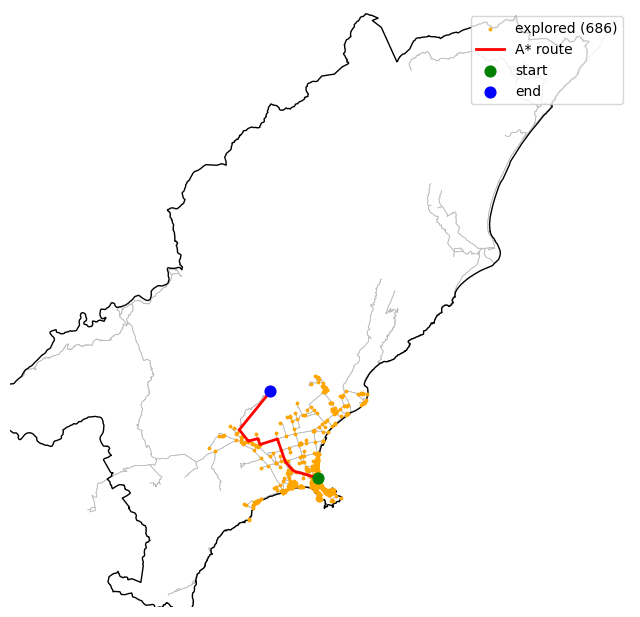

In [ ]:
"""
Run the full Phase 1 pipeline.

Load AOI -> build graph -> snap start/end -> run A* -> validate against
NetworkX Dijkstra -> print route stats -> save route (GeoPackage) and plot (PNG).
"""
aoi, poly = load_aoi(AOI_SHP, BUFFER_M)
G = build_graph(poly)
print(f"Graph: {len(G.nodes)} nodes, {len(G.edges)} edges")

src, d_src = snap(G, START_LONLAT)
dst, d_dst = snap(G, END_LONLAT)
print(f"Snap distance (m): start={d_src:.0f}, end={d_dst:.0f}")

route, cost_s, explored = astar(G, src, dst)

# validation against NetworkX
ref = nx.shortest_path_length(G, src, dst, weight="travel_time")
assert math.isclose(cost_s, ref, rel_tol=1e-9), (cost_s, ref)

rgdf = ox.routing.route_to_gdf(G, route, weight="travel_time")
print(f"Route: {len(route)} nodes, {rgdf['length'].sum() / 1000:.2f} km, {cost_s / 60:.1f} min")
print(f"Nodes explored: {len(explored)} / {len(G.nodes)}")

rgdf.to_file(OUT_GPKG, layer="route", driver="GPKG")
plot_result(G, aoi, route, explored, src, dst, OUT_PNG)
print(f"Saved {OUT_PNG}, {OUT_GPKG}")

In [ ]:
a = gpd.read_file(AOI_SHP)
print(a.crs, a.total_bounds)
aoi, poly = load_aoi(AOI_SHP, BUFFER_M)
print(poly.bounds)   # (minlon, minlat, maxlon, maxlat)

EPSG:4326 [173.18065147 -42.56542942 174.06343993 -41.9073731 ]
(173.11995753990328, -42.61045442142447, 174.1237438287957, -41.86234373380996)


## Phase 2 - Off-road routing (added cells - existing cells above are unchanged)

**Goal:** let a route leave the road when it has to - e.g. to reach a goal point that is far from any road, or to get around a blocked road - and price that off-road travel in realistic travel time so the existing `astar()` can compare road and off-road options fairly.

**Method (hybrid road + off-road):**
1. Build a grid of small squares (cells) over a window around the point of interest, at `RES_M` metres.
2. Give every cell an elevation (post-quake LINZ 2016-2017 lidar, 1 m, read from the public `s3://nz-elevation` bucket) and a land cover (ESA WorldCover 10 m, 2021).
3. Price every move between neighbouring cells (8 directions) in seconds:
   - `grade` = rise / run along the move (positive = uphill), `side` = cross-slope of the ground perpendicular to the move.
   - Move is impossible (NO-GO) if `|grade| > grade_max`, `side > side_max`, or either cell's land cover is impassable or has no elevation data.
   - Speed (km/h) = `v_lc x f(grade)`, with `f = 1 - grade/grade_max` uphill and `f = 1 - 0.5 x |grade|/grade_max` downhill (speed falls linearly to zero at the vehicle's limit, after FM 5-33's slope factor).
   - `v_lc` = land-cover speed from `LC_SPEED_KPH`; time = half the move in each cell at that cell's speed.
4. Run Dijkstra on that grid (scipy, fast C code) from the off-road point (or from each end of a blocked road segment) to every road node in the window.
5. Add those results to a copy of the road graph as `highway="offroad"` edges with `travel_time`, `length`, `speed_kph` and the real path `geometry`, then run the **unchanged** `astar()` and the same Dijkstra check as Phase 1.

**Vehicles (Kaikoura 2016 Army convoy = MHOV trucks + a Pinzgauer ambulance):**

| Profile | Spec max gradient | Spec max side slope | Source |
|---|---|---|---|
| `pinzgauer` - NZLOV (New Zealand Light Operational Vehicle) | 100% | 43.5 deg | Wikipedia: Steyr-Puch Pinzgauer |
| `mhov` - MHOV (Medium and Heavy Operational Vehicle), Rheinmetall MAN HX60 | 60% | 40% | Wikipedia: RMMV HX range |

Limits are multiplied by `SAFETY` (default 0.5) because spec figures are for firm, dry ground.

**Assumptions to revisit (all are parameters below):** land-cover speeds and impassable classes are educated guesses; WorldCover is 2021 not 2016; gaps in the 2016-2017 lidar are filled from LINZ's national 1 m then 8 m DEMs (the second data cell); road cells are always passable; if the vehicle cannot reach a point, the crew walks the last leg in a straight line at WALK_KPH (the second linking cell); off-road links are only added at off-road start/end points and at blocked-segment ends (not at every road node).

In [ ]:
### Phase 2 setup - libraries and configuration
"""
Off-road routing configuration. Edit values here; nothing in Phase 1 is changed.
Requires: rasterio (installed below), scipy, numpy, shapely, networkx, osmnx (Phase 1).
"""
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)

import json
import os
import urllib.request

import numpy as np
import rasterio
from rasterio.merge import merge
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling, transform_bounds
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from shapely.geometry import LineString, Point, box

##### GDAL settings for fast anonymous reads of cloud-optimised GeoTIFFs over HTTPS
os.environ.update({
    "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",
    "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": ".tif,.tiff",
    "GDAL_HTTP_MULTIRANGE": "YES",
    "GDAL_HTTP_MERGE_CONSECUTIVE_RANGES": "YES",
})

##### Data sources
DEM_COLLECTION = ("https://nz-elevation.s3.ap-southeast-2.amazonaws.com/"
                  "canterbury/kaikoura_2016-2017/dem_1m/2193/collection.json")  # post-quake lidar, captured Dec 2016 - Jan 2017
WC_URL = ("https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/"
          "ESA_WorldCover_10m_2021_v200_{tile}_Map.tif")                       # ESA WorldCover 2021, 3x3 degree tiles

##### Grid and window
RES_M = 20            # cell size in metres (10 = finer but ~4x slower)
WINDOW_M = 8000       # half-width of the square off-road search window around a point
SNAP_LIMIT_M = 100    # start/end further than this from a road gets off-road access links

##### Vehicle profiles (spec maxima; derated by SAFETY)
SAFETY = 0.5
VEHICLES = {
    "pinzgauer": {"label": "Pinzgauer (NZLOV)", "grade_max": 1.00, "side_max": math.tan(math.radians(43.5))},
    "mhov":      {"label": "MHOV (Rheinmetall MAN HX60)", "grade_max": 0.60, "side_max": 0.40},
}
VEHICLE = "pinzgauer"

##### Off-road speed by ESA WorldCover class (km/h); None = impassable. Educated guesses - edit freely.
LC_SPEED_KPH = {
    10: None,   # tree cover (native bush / plantation): impassable off-track
    20: 5,      # shrubland (matagouri, scrub)
    30: 30,     # grassland (pasture, tussock)
    40: 20,     # cropland
    50: 10,     # built-up (fences, buildings, yards)
    60: 15,     # bare / sparse vegetation (scree, gravel riverbeds)
    70: None,   # snow and ice
    80: None,   # permanent water
    90: None,   # herbaceous wetland
    95: None,   # mangroves
    100: 10,    # moss and lichen
}

##### Return (grade_max, side_max) as rise/run ratios after applying SAFETY
def vehicle_limits(name=None):
    """Return (grade_max, side_max) as rise/run ratios after applying SAFETY."""
    v = VEHICLES[name or VEHICLE]
    return v["grade_max"] * SAFETY, v["side_max"] * SAFETY

g_lim, s_lim = vehicle_limits()
print(f"{VEHICLES[VEHICLE]['label']}: grade limit {math.degrees(math.atan(g_lim)):.1f} deg, "
      f"side-slope limit {math.degrees(math.atan(s_lim)):.1f} deg, grid {RES_M} m")

Pinzgauer (NZLOV): grade limit 26.6 deg, side-slope limit 25.4 deg, grid 20 m


In [ ]:
### Phase 2 data - elevation and land cover on a common NZTM grid

##### Tile index for the post-quake lidar (fetched once, cached in memory)
_DEM_TILES = None

##### List the 2016-2017 Kaikoura lidar DEM tiles with their NZTM bounds
def dem_tile_index():
    """
    List the 2016-2017 Kaikoura lidar DEM tiles with their NZTM bounds.

    Reads the STAC collection, then each item's JSON (small files) to get the
    GeoTIFF URL and footprint. Cached after the first call.

    Returns:
        list of (url, (xmin, ymin, xmax, ymax)) in EPSG:2193.
    """
    global _DEM_TILES
    if _DEM_TILES is not None:
        return _DEM_TILES
    base = DEM_COLLECTION.rsplit("/", 1)[0] + "/"
    coll = json.load(urllib.request.urlopen(DEM_COLLECTION))
    tiles = []
    for link in coll["links"]:
        if link["rel"] != "item":
            continue
        item = json.load(urllib.request.urlopen(base + link["href"].lstrip("./")))
        href = next(a["href"] for a in item["assets"].values() if a["href"].endswith((".tif", ".tiff")))
        url = href if href.startswith("http") else base + href.lstrip("./")
        bounds = transform_bounds("EPSG:4326", CRS_NZTM, *item["bbox"])
        tiles.append((url, bounds))
    _DEM_TILES = tiles
    return tiles


##### Define a square grid centred on (cx, cy) in NZTM, snapped to whole cells
def make_grid(cx, cy, half_m, res=None):
    """
    Define a square grid centred on (cx, cy) in NZTM, snapped to whole cells.

    Returns:
        transform: rasterio affine transform (top-left origin).
        shape: (rows, cols).
        bounds: (xmin, ymin, xmax, ymax).
    """
    res = res or RES_M
    xmin = math.floor((cx - half_m) / res) * res
    ymax = math.ceil((cy + half_m) / res) * res
    cols = rows = int(round(2 * half_m / res))
    return from_origin(xmin, ymax, res, res), (rows, cols), (xmin, ymax - rows * res, xmin + cols * res, ymax)


##### Read the post-quake lidar for `bounds` at `res` metres (averaged from 1 m)
def load_dem(bounds, res=None):
    """
    Read the post-quake lidar for `bounds` at `res` metres (averaged from 1 m).

    Uses rasterio.merge, which reads decimated (overview) data from the
    cloud-optimised GeoTIFFs, so only the needed bytes are downloaded.

    Returns:
        2-D float array (NaN where the survey has no data).
    """
    res = res or RES_M
    xmin, ymin, xmax, ymax = bounds
    rows, cols = int(round((ymax - ymin) / res)), int(round((xmax - xmin) / res))
    hits = [u for u, b in dem_tile_index() if b[0] < xmax and b[2] > xmin and b[1] < ymax and b[3] > ymin]
    if not hits:
        return np.full((rows, cols), np.nan)
    srcs = [rasterio.open(u) for u in hits]
    try:
        arr, _ = merge(srcs, bounds=bounds, res=res, nodata=-9999, resampling=Resampling.average)
    finally:
        for s in srcs:
            s.close()
    dem = arr[0].astype("float64")[:rows, :cols]
    dem[dem <= -9998] = np.nan
    return dem


##### Names of the 3x3 degree WorldCover tiles that cover the window
def worldcover_tiles(bounds):
    """Names of the 3x3 degree WorldCover tiles covering NZTM `bounds` (e.g. 'S45E171')."""
    w, s, e, n = transform_bounds(CRS_NZTM, "EPSG:4326", *bounds)
    names = set()
    for lat0 in range(int(math.floor(s / 3) * 3), int(math.floor(n / 3) * 3) + 1, 3):
        for lon0 in range(int(math.floor(w / 3) * 3), int(math.floor(e / 3) * 3) + 1, 3):
            names.add(f"{'N' if lat0 >= 0 else 'S'}{abs(lat0):02d}{'E' if lon0 >= 0 else 'W'}{abs(lon0):03d}")
    return sorted(names)


##### Reproject ESA WorldCover classes onto the grid (mode of the 10 m pixels per cell)
def load_landcover(transform, shape, bounds):
    """
    Reproject ESA WorldCover classes onto the grid (mode of the 10 m pixels per cell).

    Returns:
        2-D uint8 array of WorldCover class codes (0 = no data).
    """
    out = np.zeros(shape, dtype="uint8")
    for name in worldcover_tiles(bounds):
        with rasterio.open(WC_URL.format(tile=name)) as src:
            tmp = np.zeros(shape, dtype="uint8")
            reproject(rasterio.band(src, 1), tmp, dst_transform=transform, dst_crs=CRS_NZTM,
                      resampling=Resampling.mode, src_nodata=0, dst_nodata=0)
            out = np.where(out == 0, tmp, out)
    return out


##### Build the terrain window around (cx, cy): grid definition, DEM and land cover
def load_terrain(cx, cy, half_m=None, res=None):
    """
    Build the terrain window around (cx, cy): grid definition, DEM and land cover.

    Returns:
        dict with transform, shape, bounds, res, dem, lc, and coverage stats.
    """
    half_m, res = half_m or WINDOW_M, res or RES_M
    transform, shape, bounds = make_grid(cx, cy, half_m, res)
    dem = load_dem(bounds, res)
    lc = load_landcover(transform, shape, bounds)
    t = {"transform": transform, "shape": shape, "bounds": bounds, "res": res, "dem": dem, "lc": lc}
    print(f"Terrain {shape[1]}x{shape[0]} cells @ {res} m | lidar coverage {np.isfinite(dem).mean():.0%} "
          f"| land cover coverage {(lc > 0).mean():.0%}")
    return t

In [ ]:
### Phase 2 data - fill lidar gaps (added after the first run: the goal point lies outside the 2016-2017 survey)
"""
The post-quake survey only covers a corridor (about 39% of the 16 km window around END_LONLAT,
and no data within 500 m of the goal), so every cell outside it was NO-GO.
Gaps are now filled in priority order, all from the same public LINZ bucket and datum (NZVD2016):
  1. Kaikoura 2016-2017 lidar, 1 m      (post-quake, preferred)
  2. LINZ national lidar DEM, 1 m       (best available per area, mostly 2018+ so also post-quake)
  3. LINZ national DEM from contours, 8 m (covers all of New Zealand; coarser and pre-quake)
DEM_SOURCE records which source filled each cell (1, 2, 3; 0 = still empty).
"""
from concurrent.futures import ThreadPoolExecutor

DEM_FALLBACKS = [
    "https://nz-elevation.s3.ap-southeast-2.amazonaws.com/new-zealand/new-zealand/dem_1m/2193/collection.json",
    "https://nz-elevation.s3.ap-southeast-2.amazonaws.com/new-zealand/new-zealand-contour/dem_8m/2193/collection.json",
]
_STAC_CACHE = {}

##### (url, NZTM bounds) of every GeoTIFF in a LINZ STAC collection
def stac_tiles(collection_url):
    """(url, NZTM bounds) of every GeoTIFF in a LINZ STAC collection; item JSONs read in parallel, cached."""
    if collection_url not in _STAC_CACHE:
        base = collection_url.rsplit("/", 1)[0] + "/"
        coll = json.load(urllib.request.urlopen(collection_url))
        hrefs = [l["href"] for l in coll["links"] if l["rel"] == "item"]

        def one(h):
            item = json.load(urllib.request.urlopen(base + h.lstrip("./")))
            href = next(a["href"] for a in item["assets"].values() if a["href"].endswith((".tif", ".tiff")))
            url = href if href.startswith("http") else base + href.lstrip("./")
            return url, transform_bounds("EPSG:4326", CRS_NZTM, *item["bbox"])

        with ThreadPoolExecutor(32) as ex:
            _STAC_CACHE[collection_url] = list(ex.map(one, hrefs))
    return _STAC_CACHE[collection_url]


##### Mosaic the tiles that touch `bounds` at `res` metres
def _read_tiles(tiles, bounds, res, rows, cols):
    """Mosaic the tiles that touch `bounds` at `res` metres; NaN where there is no data."""
    xmin, ymin, xmax, ymax = bounds
    hits = [u for u, b in tiles if b[0] < xmax and b[2] > xmin and b[1] < ymax and b[3] > ymin]
    if not hits:
        return np.full((rows, cols), np.nan)
    srcs = [rasterio.open(u) for u in hits]
    try:
        arr, _ = merge(srcs, bounds=bounds, res=res, nodata=-9999, resampling=Resampling.average)
    finally:
        for s in srcs:
            s.close()
    out = arr[0].astype("float64")[:rows, :cols]
    out[out <= -9998] = np.nan
    return out


DEM_SOURCE = None

##### Elevation: Kaikoura 2016-2017 lidar first, gaps filled from the national 1 m and 8 m DEMs
def load_dem(bounds, res=None):
    """
    Elevation for `bounds` at `res` metres: Kaikoura 2016-2017 lidar first, gaps filled from the
    national 1 m lidar DEM, then the national 8 m DEM. Replaces the earlier load_dem (same signature).
    """
    global DEM_SOURCE
    res = res or RES_M
    xmin, ymin, xmax, ymax = bounds
    rows, cols = int(round((ymax - ymin) / res)), int(round((xmax - xmin) / res))
    dem = _read_tiles(dem_tile_index(), bounds, res, rows, cols)
    src = np.where(np.isfinite(dem), 1, 0).astype("uint8")
    for i, url in enumerate(DEM_FALLBACKS, start=2):
        gap = ~np.isfinite(dem)
        if not gap.any():
            break
        fill = _read_tiles(stac_tiles(url), bounds, res, rows, cols)
        use = gap & np.isfinite(fill)
        dem[use], src[use] = fill[use], i
    DEM_SOURCE = src
    print(f"DEM sources: Kaikoura 2016-17 lidar {(src == 1).mean():.0%}, national 1 m {(src == 2).mean():.0%}, "
          f"national 8 m {(src == 3).mean():.0%}, none {(src == 0).mean():.0%}")
    return dem


In [ ]:
### Phase 2 cost model - directed grid graph of off-road travel times

##### The 8 moves from a cell: (row offset, col offset)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]


##### Turn a terrain window into a directed sparse graph of travel times (seconds)
def build_offroad_graph(t, vehicle=None, lc_speed=None):
    """
    Turn a terrain window into a directed sparse graph of travel times (seconds).

    Node = cell index (row * cols + col). Edge a->b exists for each of the 8
    neighbours when the move is possible for the vehicle:
      grade = (z_b - z_a) / move length          (rise over run, + = uphill)
      side  = |cross-slope| of the ground perpendicular to the move (mean of a and b)
      NO-GO if |grade| > grade_max, side > side_max, missing elevation,
      or impassable land cover in a or b.
      speed_cell = LC speed x f(grade); f = 1 - grade/grade_max uphill,
                   f = 1 - 0.5*|grade|/grade_max downhill.
      time = (L/2)/speed_a + (L/2)/speed_b.

    Args:
        t: terrain dict from load_terrain().
        vehicle: key in VEHICLES (default VEHICLE).
        lc_speed: land-cover speed table (default LC_SPEED_KPH).

    Returns:
        csr_matrix (N x N) of travel times in seconds.
    """
    grade_max, side_max = vehicle_limits(vehicle)
    lc_speed = lc_speed or LC_SPEED_KPH
    dem, lc, res = t["dem"], t["lc"], t["res"]
    rows, cols = dem.shape

    ##### Per-cell base speed (m/s) from land cover; NaN = impassable
    lut = np.full(256, np.nan)
    for code, kph in lc_speed.items():
        if kph:
            lut[code] = kph / 3.6
    v_lc = lut[lc]
    v_lc[~np.isfinite(dem)] = np.nan

    ##### Ground gradient per cell (dz/dx east, dz/dy north), for side slope
    gy, gx = np.gradient(dem, res)   # gy is along rows (south-ward), so north = -gy
    gn = -gy

    idx = np.arange(rows * cols).reshape(rows, cols)
    src_all, dst_all, w_all = [], [], []
    for dr, dc in MOVES:
        ##### Slices for source a and destination b = a + (dr, dc)
        ra = slice(max(0, -dr), rows - max(0, dr)); ca = slice(max(0, -dc), cols - max(0, dc))
        rb = slice(max(0, dr), rows - max(0, -dr)); cb = slice(max(0, dc), cols - max(0, -dc))
        L = res * math.hypot(dr, dc)
        ux, uy = dc / math.hypot(dr, dc), -dr / math.hypot(dr, dc)   # unit move vector (east, north)
        za, zb = dem[ra, ca], dem[rb, cb]
        grade = (zb - za) / L
        ##### Cross-slope = |gradient x move direction|, averaged over the two cells
        side = 0.5 * (np.abs(gx[ra, ca] * uy - gn[ra, ca] * ux) + np.abs(gx[rb, cb] * uy - gn[rb, cb] * ux))
        f = np.where(grade >= 0, 1 - grade / grade_max, 1 - 0.5 * np.abs(grade) / grade_max)
        va, vb = v_lc[ra, ca] * f, v_lc[rb, cb] * f
        ok = (np.abs(grade) <= grade_max) & (side <= side_max) & (va > 0) & (vb > 0)
        ok &= np.isfinite(va) & np.isfinite(vb)
        with np.errstate(divide="ignore", invalid="ignore"):
            w = (L / 2) / va + (L / 2) / vb
        src_all.append(idx[ra, ca][ok]); dst_all.append(idx[rb, cb][ok]); w_all.append(w[ok])
    n = rows * cols
    m = coo_matrix((np.concatenate(w_all), (np.concatenate(src_all), np.concatenate(dst_all))), shape=(n, n))
    return m.tocsr()


##### Cell index for NZTM (x, y), or None if outside the window
def xy_to_cell(t, x, y):
    """Cell index for NZTM (x, y), or None if outside the window."""
    col, row = ~t["transform"] * (x, y)
    r, c = int(math.floor(row)), int(math.floor(col))
    rows, cols = t["shape"]
    return r * cols + c if 0 <= r < rows and 0 <= c < cols else None


##### NZTM (x, y) of the centre of cell index i
def cell_to_xy(t, i):
    """NZTM (x, y) of the centre of cell index i."""
    rows, cols = t["shape"]
    x, y = t["transform"] * ((i % cols) + 0.5, (i // cols) + 0.5)
    return x, y


##### Rebuild the list of cell indices from source to target using a predecessor array
def trace(pred, target, source):
    """Rebuild the list of cell indices from source to target using a predecessor array."""
    path = [target]
    while path[-1] != source:
        p = pred[path[-1]]
        if p < 0:
            return None
        path.append(p)
    return path[::-1]

In [ ]:
### Phase 2 linking - add off-road edges to a copy of the road graph

def _road_nodes_in(G, t):
    """Road nodes (not off-road helper nodes) inside the terrain window, with their cell index."""
    out = []
    for n, d in G.nodes(data=True):
        if d.get("offroad_point"):
            continue
        c = xy_to_cell(t, d["x"], d["y"])
        if c is not None:
            out.append((n, c))
    return out


##### Add one off-road edge u->v with travel_time, length, speed_kph and the cell path as geometry
def _add_offroad_edge(G, u, v, cells, t, seconds):
    """Add one off-road edge u->v with travel_time, length, speed_kph and the cell path as geometry."""
    pts = [cell_to_xy(t, c) for c in cells]
    pts = [(G.nodes[u]["x"], G.nodes[u]["y"])] + pts + [(G.nodes[v]["x"], G.nodes[v]["y"])]
    geom = LineString(pts)
    ##### Never faster than a straight line at the top off-road speed (keeps A*'s heuristic admissible)
    straight = math.dist(pts[0], pts[-1])
    v_top = max(k for k in LC_SPEED_KPH.values() if k) / 3.6
    seconds = max(float(seconds), straight / v_top, 1e-3)
    # no key given: networkx assigns a new one, so an existing road edge u->v is never overwritten
    G.add_edge(u, v, highway="offroad", offroad=True, travel_time=seconds,
               length=float(geom.length), speed_kph=straight / seconds * 3.6, geometry=geom)


##### Connect `node` to every reachable road node in the terrain window by off-road edges
def add_offroad_links(G, node, t, M, direction="out", exclude=()):
    """
    Connect `node` to every reachable road node in the terrain window by off-road edges.

    direction="out": edges node -> road nodes (leaving from an off-road start, or
                     from the end of a blocked segment).
    direction="in":  edges road nodes -> node (arriving at an off-road goal).
    One Dijkstra run on the grid (or on its transpose for "in") prices all links at once.

    Args:
        G: graph to modify in place (projected, NZTM).
        node: node id already in G with x/y.
        t: terrain dict; M: grid graph from build_offroad_graph(t).
        direction: "out" or "in".
        exclude: node ids not to link to.

    Returns:
        number of edges added.
    """
    c0 = xy_to_cell(t, G.nodes[node]["x"], G.nodes[node]["y"])
    if c0 is None:
        raise ValueError("node is outside the terrain window")
    graph = M if direction == "out" else M.T.tocsr()
    dist, pred = dijkstra(graph, directed=True, indices=c0, return_predecessors=True)
    added = 0
    for n, c in _road_nodes_in(G, t):
        if n == node or n in exclude or not np.isfinite(dist[c]):
            continue
        cells = trace(pred, c, c0)
        if cells is None:
            continue
        if direction == "out":
            _add_offroad_edge(G, node, n, cells, t, dist[c])
        else:
            _add_offroad_edge(G, n, node, cells[::-1], t, dist[c])
        added += 1
    return added


##### Add an off-road start ("start") or goal ("end") point to G and link it to nearby roads
def add_offroad_point(G, lonlat, node_id, role):
    """
    Add an off-road start ("start") or goal ("end") point to G and link it to nearby roads.

    Returns:
        (terrain dict, number of links added).
    """
    x, y = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*lonlat)
    G.add_node(node_id, x=x, y=y, offroad_point=True, street_count=0)
    t = load_terrain(x, y)
    M = build_offroad_graph(t)
    n = add_offroad_links(G, node_id, t, M, direction="out" if role == "start" else "in")
    print(f"{role}: {n} off-road links to road nodes within {WINDOW_M/1000:.0f} km")
    return t, n


##### Cut roads at each blockage, then let vehicles leave the road at every cut end
def block_and_bypass(G, blockages, window_m=None):
    """
    Apply blockages (e.g. landslide footprints) to the road graph and the terrain, then let
    vehicles leave the road at the ends of every cut road segment.

    1. Road edges whose geometry touches a blockage polygon are removed (both directions).
    2. The terrain window is loaded around the blockages and cells inside them are made NO-GO,
       so an off-road bypass cannot simply drive through the slip.
    3. Each end node of a removed edge gets off-road links to nearby road nodes.

    Args:
        G: graph to modify in place (projected, NZTM).
        blockages: list of shapely polygons in NZTM.
        window_m: half-width of the terrain window (default WINDOW_M).

    Returns:
        (terrain dict, list of removed (u, v) pairs).
    """
    from rasterio.features import geometry_mask
    window_m = window_m or WINDOW_M
    removed = []
    for u, v, k, d in list(G.edges(keys=True, data=True)):
        geom = d.get("geometry") or LineString([(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])
        if any(geom.intersects(p) for p in blockages):
            G.remove_edge(u, v, k)
            removed.append((u, v))
    ends = sorted({n for e in removed for n in e})
    if not ends:
        raise ValueError("no road edge touches the blockages")
    ##### One terrain window centred on the blockages; slip cells become NO-GO (no elevation)
    c = gpd.GeoSeries(blockages).union_all().centroid
    t = load_terrain(c.x, c.y, window_m)
    inside = ~geometry_mask(blockages, out_shape=t["shape"], transform=t["transform"])
    t["dem"][inside] = np.nan
    M = build_offroad_graph(t)
    for n in ends:
        if xy_to_cell(t, G.nodes[n]["x"], G.nodes[n]["y"]) is None:
            print(f"cut-segment end {n}: outside the {window_m/1000:.0f} km window - no bypass links (increase window_m)")
            continue
        k = add_offroad_links(G, n, t, M, direction="out")
        print(f"cut-segment end {n}: {k} off-road bypass links")
    return t, removed

In [ ]:
### Phase 2 linking fixes - roads are passable cells, and a foot leg when the vehicle cannot get there
"""
Two problems found on the first real run (both now handled here; earlier cells are unchanged):
  1. Road nodes inside bush (WorldCover class 10) sat in NO-GO cells, so they could never be an
     off-road entry or exit point. Fix: every cell a road passes through becomes class ROAD_LC
     (speed LC_SPEED_KPH[ROAD_LC]), and moves between two road cells skip the slope tests
     (the road is benched into the hillside; the 20 m DEM only sees the hillside).
  2. The goal point is on a 25 deg slope in a pocket of 26 cells that the derated Pinzgauer
     cannot leave. In 2016 places with no ground route were reached by air (helicopter) and sea, so
     the model now says "no ground route - air support most likely". Optional (ALLOW_WALK_LEG = True):
     drive to the best reachable cell and the crew walks the rest in a straight line at WALK_KPH.
"""
from rasterio.features import rasterize

ROAD_LC = 254
LC_SPEED_KPH[ROAD_LC] = 20      # crossing / joining a road from the terrain grid (km/h)
ALLOW_WALK_LEG = True            # False = stop at "no ground route" instead of adding a walking last leg
WALK_KPH = 3                     # crew on foot over steep hill country (ignores slope; an assumption)


##### Set land cover to ROAD_LC in every cell touched by a road edge of G_roads (in place)
def mark_roads(t, G_roads):
    """Set land cover to ROAD_LC in every cell touched by a road edge of G_roads (in place)."""
    shapes = []
    for u, v, d in G_roads.edges(data=True):
        if d.get("offroad"):
            continue
        shapes.append(d.get("geometry") or LineString([(G_roads.nodes[u]["x"], G_roads.nodes[u]["y"]),
                                                       (G_roads.nodes[v]["x"], G_roads.nodes[v]["y"])]))
    road = rasterize([(s, 1) for s in shapes], out_shape=t["shape"], transform=t["transform"],
                     all_touched=True, dtype="uint8").astype(bool)
    t["lc"][road] = ROAD_LC
    t["road"] = road
    return t


if "_load_terrain_base" not in globals():
    _load_terrain_base = load_terrain
    _build_offroad_graph_base = build_offroad_graph

##### Same as before, plus road cells marked passable (uses the Phase 1 road graph G)
def load_terrain(cx, cy, half_m=None, res=None):
    """Same as before, plus road cells marked passable (uses the Phase 1 road graph G)."""
    return mark_roads(_load_terrain_base(cx, cy, half_m, res), G)

##### Same as before, plus slope-free moves between adjacent road cells (with elevation data)
def build_offroad_graph(t, vehicle=None, lc_speed=None):
    """Same as before, plus slope-free moves between adjacent road cells (with elevation data)."""
    M = _build_offroad_graph_base(t, vehicle, lc_speed)
    road = t.get("road")
    if road is None:
        return M
    rows, cols = t["shape"]
    ok_cell = road & np.isfinite(t["dem"])
    v = (lc_speed or LC_SPEED_KPH)[ROAD_LC] / 3.6
    idx = np.arange(rows * cols).reshape(rows, cols)
    src, dst, w = [], [], []
    for dr, dc in MOVES:
        ra = slice(max(0, -dr), rows - max(0, dr)); ca = slice(max(0, -dc), cols - max(0, dc))
        rb = slice(max(0, dr), rows - max(0, -dr)); cb = slice(max(0, dc), cols - max(0, -dc))
        ok = ok_cell[ra, ca] & ok_cell[rb, cb]
        src.append(idx[ra, ca][ok]); dst.append(idx[rb, cb][ok])
        w.append(np.full(ok.sum(), t["res"] * math.hypot(dr, dc) / v))
    extra = coo_matrix((np.concatenate(w), (np.concatenate(src), np.concatenate(dst))), shape=M.shape).tocsr()
    ##### Road-to-road moves replace any graded move between the same cells (never slower: same speed, f <= 1)
    return (M - M.multiply(extra > 0) + extra).tocsr()


##### Straight-line walking edge u->v at WALK_KPH
def _add_foot_edge(G, u, v):
    """Straight-line walking edge u->v at WALK_KPH."""
    a, b = (G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])
    L = max(math.dist(a, b), 1e-3)
    G.add_edge(u, v, highway="foot", offroad=True, foot=True, travel_time=L / (WALK_KPH / 3.6),
               length=L, speed_kph=WALK_KPH, geometry=LineString([a, b]))


##### Add an off-road start ("start") or goal ("end") point to G and link it to nearby roads
def add_offroad_point(G, lonlat, node_id, role):
    """
    Add an off-road start ("start") or goal ("end") point to G and link it to nearby roads.
    If the vehicle cannot reach the point, add a dismount node at the reachable cell that
    minimises (grid drive time from the nearest road node + walking time), link it to the
    roads, and join it to the point with a foot edge.

    Returns:
        (terrain dict, number of links added).
    """
    x, y = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*lonlat)
    G.add_node(node_id, x=x, y=y, offroad_point=True, street_count=0)
    t = load_terrain(x, y)
    M = build_offroad_graph(t)
    direction = "out" if role == "start" else "in"
    n = add_offroad_links(G, node_id, t, M, direction=direction)
    print(f"{role}: {n} off-road links to road nodes within {WINDOW_M/1000:.0f} km")
    if n:
        return t, n
    print(f"{role}: no ground route for {VEHICLES[VEHICLE]['label']} - air support (helicopter) is the most likely "
          f"option, as in 2016" + ("" if ALLOW_WALK_LEG else "; set ALLOW_WALK_LEG = True to model a walking last leg"))
    if not ALLOW_WALK_LEG:
        raise nx.NetworkXNoPath(f"{role}: no ground route - air support needed")
    ##### Optional walking leg: find the best dismount cell
    seeds = [c for _, c in _road_nodes_in(G, t)]
    graph = M if role == "end" else M.T.tocsr()          # end: roads -> cell; start: cell -> roads
    drive = dijkstra(graph, directed=True, indices=seeds, min_only=True)
    rows, cols = t["shape"]
    cx, cy = np.meshgrid(np.arange(cols) + 0.5, np.arange(rows) + 0.5)
    X, Y = t["transform"] * (cx, cy)
    walk = np.hypot(X - x, Y - y).ravel() / (WALK_KPH / 3.6)
    total = np.where(np.isfinite(drive), drive + walk, np.inf)
    best = int(np.argmin(total))
    if not np.isfinite(total[best]):
        raise nx.NetworkXNoPath(f"{role}: no road node in the window is reachable by the vehicle")
    bx, by = cell_to_xy(t, best)
    dm = f"{node_id}_dismount"
    G.add_node(dm, x=bx, y=by, offroad_point=True, street_count=0)
    n = add_offroad_links(G, dm, t, M, direction=direction)
    if role == "end":
        _add_foot_edge(G, dm, node_id)
    else:
        _add_foot_edge(G, node_id, dm)
    print(f"{role}: walking-leg option - dismount point {math.dist((bx, by), (x, y)):.0f} m away "
          f"({walk[best]/60:.0f} min on foot at {WALK_KPH} km/h), {n} off-road links from it")
    return t, n


In [ ]:
### Phase 2 self-tests - cost model on synthetic terrain (no downloads)

def _synthetic(dem, lc_code=30, res=20):
    """Terrain dict for a synthetic DEM with uniform land cover."""
    rows, cols = dem.shape
    return {"transform": from_origin(0, rows * res, res, res), "shape": dem.shape, "bounds": (0, 0, cols * res, rows * res),
            "res": res, "dem": dem.astype(float), "lc": np.full(dem.shape, lc_code, dtype="uint8")}

##### Check the cost model on tiny synthetic terrains (inside a function so notebook variables are untouched)
def _run_selftests():
    """Check the cost model on tiny synthetic terrains (kept in a function so no notebook variables are overwritten)."""
    g_lim, s_lim = vehicle_limits()
    v_grass = LC_SPEED_KPH[30] / 3.6

    ##### 1. Flat grassland: 50 cells east = 1000 m at grass speed
    t = _synthetic(np.zeros((5, 60)))
    d = dijkstra(build_offroad_graph(t), indices=2 * 60 + 5)
    assert math.isclose(d[2 * 60 + 55], 1000 / v_grass, rel_tol=1e-9), d[2 * 60 + 55]

    ##### 2. Uphill is slower than downhill on the same ramp (grade = half the limit)
    ramp = np.tile(np.arange(60) * 20 * (g_lim / 2), (5, 1))
    M = build_offroad_graph(_synthetic(ramp))
    up = dijkstra(M, indices=2 * 60 + 5)[2 * 60 + 55]
    down = dijkstra(M, indices=2 * 60 + 55)[2 * 60 + 5]
    assert math.isclose(up, 1000 / (v_grass * 0.5), rel_tol=1e-9) and math.isclose(down, 1000 / (v_grass * 0.75), rel_tol=1e-9)

    ##### 3. A slope 1.5x the vehicle limit is impassable (even diagonally, which lowers the grade by 1/sqrt(2))
    steep = np.tile(np.arange(60) * 20 * (g_lim * 1.5), (5, 1))
    assert not np.isfinite(dijkstra(build_offroad_graph(_synthetic(steep)), indices=2 * 60 + 5)[2 * 60 + 55])

    ##### 4. Impassable land cover (forest) blocks movement; water likewise
    assert build_offroad_graph(_synthetic(np.zeros((5, 5)), lc_code=10)).nnz == 0
    assert build_offroad_graph(_synthetic(np.zeros((5, 5)), lc_code=80)).nnz == 0

    ##### 5. Side slope just over the limit blocks a move ALONG the slope but not one straight down it
    side = np.tile((np.arange(5) * 20 * (s_lim * 1.05))[:, None], (1, 60))   # rises to the south
    assert s_lim * 1.05 < g_lim, "test needs side limit below grade limit"
    M = build_offroad_graph(_synthetic(side))
    a = 2 * 60 + 5
    assert M[a, a + 1] == 0          # east move: cross-slope too steep -> no edge
    assert M[a, a + 60] > 0          # south move: straight up the fall line, grade within limit -> edge
    print(f"Self-tests passed: flat {1000 / v_grass:.0f} s/km, uphill {up:.0f} s, downhill {down:.0f} s per km at half the grade limit")

_run_selftests()

Self-tests passed: flat 120 s/km, uphill 240 s, downhill 160 s per km at half the grade limit


In [ ]:
### Phase 2 plotting - route over terrain, road and off-road legs in different colours

def plot_offroad(G, route, t, title, out_png):
    """
    Plot shaded terrain (with NO-GO land cover tinted), the road network, and the route.

    Road legs = red, off-road legs = magenta dashed, start = green, end = blue.
    """
    xmin, ymin, xmax, ymax = t["bounds"]
    dem = t["dem"]
    from matplotlib.colors import LightSource
    filled = np.nan_to_num(dem, nan=np.nanmin(dem) if np.isfinite(dem).any() else 0.0)
    shade = LightSource(azdeg=315, altdeg=45).hillshade(filled, dx=t["res"], dy=t["res"])
    nogo = np.isin(t["lc"], [k for k, v in LC_SPEED_KPH.items() if not v]) | ~np.isfinite(dem)
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(shade, cmap="gray", extent=(xmin, xmax, ymin, ymax), alpha=0.8)
    ax.imshow(np.ma.masked_where(~nogo, nogo), cmap="Reds", vmin=0, vmax=2, extent=(xmin, xmax, ymin, ymax), alpha=0.35)
    for u, v, d in G.edges(data=True):
        if d.get("offroad"):
            continue
        geom = d.get("geometry") or LineString([(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])
        ax.plot(*geom.xy, color="#555555", lw=0.6)
    for a, b in zip(route[:-1], route[1:]):
        d = min(G[a][b].values(), key=lambda e: e["travel_time"])
        geom = d.get("geometry") or LineString([(G.nodes[a]["x"], G.nodes[a]["y"]), (G.nodes[b]["x"], G.nodes[b]["y"])])
        ax.plot(*geom.xy, color="magenta" if d.get("offroad") else "red", lw=2.5, ls="--" if d.get("offroad") else "-")
    ax.scatter(G.nodes[route[0]]["x"], G.nodes[route[0]]["y"], s=70, c="green", zorder=5, label="start")
    ax.scatter(G.nodes[route[-1]]["x"], G.nodes[route[-1]]["y"], s=70, c="blue", zorder=5, label="end")
    ax.plot([], [], color="red", lw=2.5, label="road leg")
    ax.plot([], [], color="magenta", lw=2.5, ls="--", label="off-road leg")
    ax.fill_between([], [], color="red", alpha=0.35, label="NO-GO land cover / no lidar")
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_title(title); ax.legend(loc="best"); ax.set_aspect("equal")
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.show()


##### Print road vs off-road distance and time for a route
def route_summary(G, route):
    """Print road vs off-road distance and time for a route; return (total seconds, off-road seconds)."""
    tot = off = 0.0
    dist_road = dist_off = 0.0
    for a, b in zip(route[:-1], route[1:]):
        d = min(G[a][b].values(), key=lambda e: e["travel_time"])
        tot += d["travel_time"]
        if d.get("offroad"):
            off += d["travel_time"]; dist_off += d["length"]
        else:
            dist_road += d["length"]
    print(f"  road: {dist_road/1000:.2f} km, {(tot-off)/60:.1f} min | off-road: {dist_off/1000:.2f} km, {off/60:.1f} min "
          f"| total {tot/60:.1f} min")
    return tot, off

In [ ]:
### Phase 2 test 1 - reach the off-road goal point (Phase 1 stopped at the nearest road)

G_off = G.copy()   # Phase 1 graph G is left untouched
START_ID, END_ID = -1, -2
start, goal, t_plot = src, dst, None

##### Add off-road access wherever the start or end is further than SNAP_LIMIT_M from a road
if d_src > SNAP_LIMIT_M:
    t_plot, _ = add_offroad_point(G_off, START_LONLAT, START_ID, "start"); start = START_ID
if d_dst > SNAP_LIMIT_M:
    t_plot, _ = add_offroad_point(G_off, END_LONLAT, END_ID, "end"); goal = END_ID

##### Same A* and the same Dijkstra check as Phase 1
route_off, cost_off, explored_off = astar(G_off, start, goal)
ref_off = nx.shortest_path_length(G_off, start, goal, weight="travel_time")
assert math.isclose(cost_off, ref_off, rel_tol=1e-9), (cost_off, ref_off)

##### Extra checks: admissible off-road edges, and route cost = sum of its edges
v_top = max(k for k in LC_SPEED_KPH.values() if k) / 3.6
for u, v, d in G_off.edges(data=True):
    if d.get("offroad"):
        straight = math.dist((G_off.nodes[u]["x"], G_off.nodes[u]["y"]), (G_off.nodes[v]["x"], G_off.nodes[v]["y"]))
        assert d["travel_time"] >= straight / v_top - 1e-6
print(f"Phase 1 (road only, stops {d_dst:.0f} m short of the goal): {cost_s / 60:.1f} min")
print(f"Phase 2 ({VEHICLES[VEHICLE]['label']}, reaches the goal):")
tot_off, _ = route_summary(G_off, route_off)
assert math.isclose(tot_off, cost_off, rel_tol=1e-9)
print(f"A* explored {len(explored_off)} / {len(G_off.nodes)} nodes; matches Dijkstra.")
if t_plot is not None:
    plot_offroad(G_off, route_off, t_plot, f"Off-road goal - {VEHICLES[VEHICLE]['label']}", "offroad_goal.png")

Road-only detour: 19.2 min
DEM sources: Kaikoura 2016-17 lidar 47%, national 1 m 8%, national 8 m 0%, none 45%
Terrain 800x800 cells @ 20 m | lidar coverage 55% | land cover coverage 100%
cut-segment end 1464471694: 618 off-road bypass links
cut-segment end 1464481065: 618 off-road bypass links
Cut road edges: [(1464471694, 1464481065), (1464481065, 1464471694)]
With off-road bypass (Pinzgauer (NZLOV)):
  road: 23.42 km, 19.2 min | off-road: 0.00 km, 0.0 min | total 19.2 min
Unblocked Phase 1 route: 18.5 min


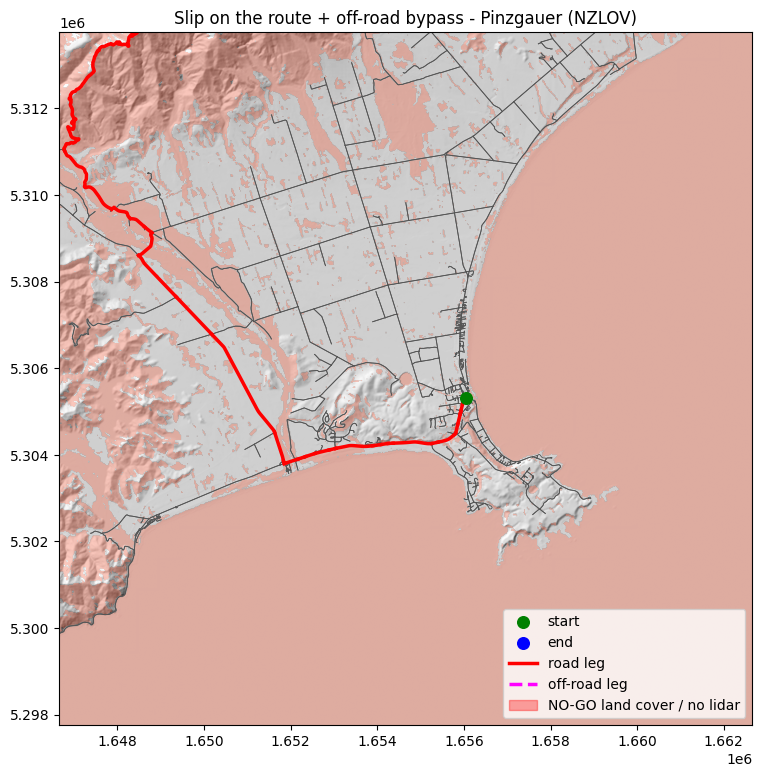

In [40]:
### Phase 2 test 2 - a landslide cuts the Phase 1 route: road-only detour vs off-road bypass

##### Stand-in blockage: a 150 m-radius "slip" at the middle of the Phase 1 route (replace with the team's blocked-road polygons)
BLOCK_RADIUS_M = 150
mid_edge = min(G[route[len(route) // 2]][route[len(route) // 2 + 1]].values(), key=lambda e: e["travel_time"])
mid_geom = mid_edge.get("geometry") or LineString([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in route[len(route) // 2:len(route) // 2 + 2]])
BLOCKAGES = [mid_geom.interpolate(0.5, normalized=True).buffer(BLOCK_RADIUS_M)]

##### A) Road-only detour
G_blk = G.copy()
for u, v, k, d in list(G_blk.edges(keys=True, data=True)):
    geom = d.get("geometry") or LineString([(G_blk.nodes[u]["x"], G_blk.nodes[u]["y"]), (G_blk.nodes[v]["x"], G_blk.nodes[v]["y"])])
    if any(geom.intersects(p) for p in BLOCKAGES):
        G_blk.remove_edge(u, v, k)
try:
    r_road, c_road, _ = astar(G_blk, src, dst)
    print(f"Road-only detour: {c_road / 60:.1f} min")
except nx.NetworkXNoPath:
    r_road, c_road = None, math.inf
    print("Road-only detour: no path - the slip cuts the road network")

##### B) Road + off-road bypass around the slip
G_byp = G.copy()
t_byp, cut = block_and_bypass(G_byp, BLOCKAGES)
print("Cut road edges:", cut)
r_byp, c_byp, _ = astar(G_byp, src, dst)
assert math.isclose(c_byp, nx.shortest_path_length(G_byp, src, dst, weight="travel_time"), rel_tol=1e-9)
assert c_byp <= c_road + 1e-6, "adding options can never make the best route slower"
print(f"With off-road bypass ({VEHICLES[VEHICLE]['label']}):")
route_summary(G_byp, r_byp)
print(f"Unblocked Phase 1 route: {cost_s / 60:.1f} min")
plot_offroad(G_byp, r_byp, t_byp, f"Slip on the route + off-road bypass - {VEHICLES[VEHICLE]['label']}", "offroad_bypass.png")

start  : Culverden, Canterbury, New Zealand -> (172.8493, -42.7727)
goal   : Kaikoura Racecourse, Kaikoura, New Zealand -> (173.6768, -42.4152)
slip 1 : Ohau Point, Kaikoura, New Zealand -> (173.8300, -42.2475)
slip 2 : Goose Bay, Kaikoura, New Zealand -> (173.5280, -42.4779)
Incident study area graph: 3310 nodes, 7604 edges
Snap distance (m): start=11, goal=35
A) no blockages:     103.9 km, 66 min, 74% on the Inland Road
B) 32 road edges cut by 2 slip zones
B) SH1 slips:        103.9 km, 66 min, 74% on the Inland Road
   Real convoy: about 100 km, about 240 min via the Inland Road
   Calibration: the convoy took 3.7x the posted-speed time (set DAMAGED_ROAD_FACTOR to that to match it)


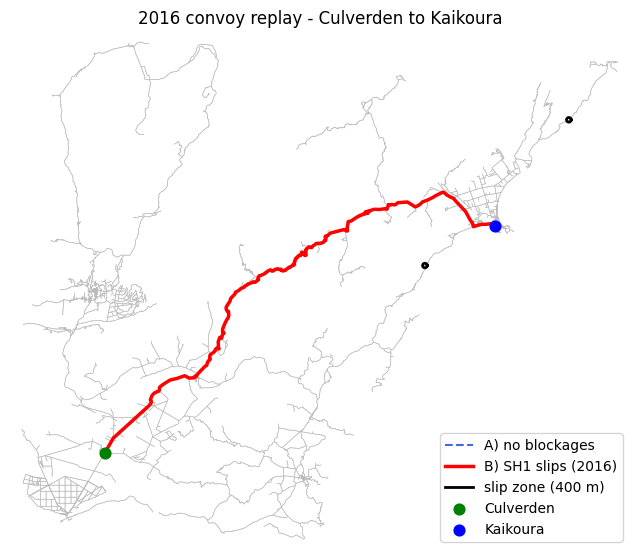

In [42]:
### Phase 2 test 3 - replay the 2016 Army convoy (Culverden -> Kaikoura) on a separate, larger study area
"""
What happened (sources in the notes): SH1 was cut by large slips on both sides of Kaikoura, so the
Army convoy of 27 trucks drove Culverden -> Waiau -> Inland Road (Route 70) -> Kaikoura racecourse,
about 100 km in about 4 hours, arriving 18 Nov 2016.

Test: build a new road graph covering Culverden, Cheviot and Kaikoura (Phase 1 G is untouched),
then route Culverden -> Kaikoura racecourse
  A) with no blockages, and
  B) with the SH1 slip zones north and south of Kaikoura blocked,
and check that B follows the Inland Road like the real convoy. Slip zones are stand-ins: a
SLIP_RADIUS_M circle at named places on SH1 (geocoded from OpenStreetMap), not mapped slip outlines.
"""
INC_PLACES = {
    "start": "Culverden, Canterbury, New Zealand",
    "goal": ["Kaikoura Racecourse, Kaikoura, New Zealand", "Kaikoura, Canterbury, New Zealand"],
}
SLIP_PLACES = ["Ohau Point, Kaikoura, New Zealand",          # SH1 north of Kaikoura
               "Goose Bay, Kaikoura, New Zealand"]           # SH1 south of Kaikoura (coast towards Oaro)
SLIP_RADIUS_M = 400
INC_MARGIN_M = 15000              # study-area margin around the start, goal and slips
DAMAGED_ROAD_FACTOR = 1.0         # multiply road travel times (1.0 = posted speeds); see calibration below
CONVOY_MIN = 240                  # real convoy: about 100 km in about 4 hours

##### (lon, lat) for a place name, trying each name in a list until one is found
def _geocode(q):
    """(lon, lat) for a place name, trying each name in a list until one is found."""
    for name in ([q] if isinstance(q, str) else q):
        try:
            lat, lon = ox.geocode(name)
            return lon, lat, name
        except Exception:
            continue
    raise ValueError(f"could not geocode {q}")

to_nztm = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True)
inc_pts = {k: _geocode(v) for k, v in INC_PLACES.items()}
slip_pts = [_geocode(p) for p in SLIP_PLACES]
for k, (lon, lat, name) in list(inc_pts.items()) + [(f"slip {i+1}", s) for i, s in enumerate(slip_pts)]:
    print(f"{k:7s}: {name} -> ({lon:.4f}, {lat:.4f})")

##### Separate study area: bounding box of all points + margin (new graph G_inc; Phase 1 G untouched)
xy = [to_nztm.transform(lon, lat) for lon, lat, _ in list(inc_pts.values()) + slip_pts]
inc_box = box(min(p[0] for p in xy), min(p[1] for p in xy), max(p[0] for p in xy), max(p[1] for p in xy)).buffer(INC_MARGIN_M)
inc_poly = gpd.GeoSeries([inc_box], crs=CRS_NZTM).to_crs("EPSG:4326").iloc[0]
G_inc = build_graph(inc_poly)
if DAMAGED_ROAD_FACTOR != 1.0:
    for _, _, d in G_inc.edges(data=True):
        d["travel_time"] *= DAMAGED_ROAD_FACTOR
        d["speed_kph"] /= DAMAGED_ROAD_FACTOR
print(f"Incident study area graph: {len(G_inc.nodes)} nodes, {len(G_inc.edges)} edges")

s_inc, ds = snap(G_inc, inc_pts["start"][:2])
g_inc, dg = snap(G_inc, inc_pts["goal"][:2])
print(f"Snap distance (m): start={ds:.0f}, goal={dg:.0f}")

##### Share of route length on edges whose OSM name mentions 'Inland' (Route 70)
def _on_inland(G, route):
    """Share of route length on edges whose OSM name mentions 'Inland' (Route 70)."""
    tot = inl = 0.0
    for a, b in zip(route[:-1], route[1:]):
        d = min(G[a][b].values(), key=lambda e: e["travel_time"])
        nm = d.get("name", "")
        nm = " ".join(nm) if isinstance(nm, list) else str(nm)
        tot += d["length"]
        inl += d["length"] if "inland" in nm.lower() else 0.0
    return tot, inl

##### A) No blockages
rA, cA, _ = astar(G_inc, s_inc, g_inc)
assert math.isclose(cA, nx.shortest_path_length(G_inc, s_inc, g_inc, weight="travel_time"), rel_tol=1e-9)
totA, inlA = _on_inland(G_inc, rA)
print(f"A) no blockages:     {totA/1000:.1f} km, {cA/60:.0f} min, {inlA/totA:.0%} on the Inland Road")

##### B) SH1 slips north and south of Kaikoura (as in Nov 2016)
INC_BLOCKAGES = [Point(to_nztm.transform(lon, lat)).buffer(SLIP_RADIUS_M) for lon, lat, _ in slip_pts]
G_incB = G_inc.copy()
cutB = []
for u, v, k, d in list(G_incB.edges(keys=True, data=True)):
    geom = d.get("geometry") or LineString([(G_incB.nodes[u]["x"], G_incB.nodes[u]["y"]), (G_incB.nodes[v]["x"], G_incB.nodes[v]["y"])])
    if any(geom.intersects(p) for p in INC_BLOCKAGES):
        G_incB.remove_edge(u, v, k); cutB.append((u, v))
print(f"B) {len(cutB)} road edges cut by {len(INC_BLOCKAGES)} slip zones")
try:
    rB, cB, _ = astar(G_incB, s_inc, g_inc)
    assert math.isclose(cB, nx.shortest_path_length(G_incB, s_inc, g_inc, weight="travel_time"), rel_tol=1e-9)
    totB, inlB = _on_inland(G_incB, rB)
    print(f"B) SH1 slips:        {totB/1000:.1f} km, {cB/60:.0f} min, {inlB/totB:.0%} on the Inland Road")
    print(f"   Real convoy: about 100 km, about {CONVOY_MIN} min via the Inland Road")
    print(f"   Calibration: the convoy took {CONVOY_MIN / (cB / 60):.1f}x the posted-speed time "
          f"(set DAMAGED_ROAD_FACTOR to that to match it)")
except nx.NetworkXNoPath:
    rB = None
    print("B) no ground route - air support (helicopter) is the most likely option, as in 2016")

##### Map: grey roads, blue = route A, red = route B, black circles = slip zones
fig, ax = ox.plot_graph(G_inc, node_size=0, edge_color="#bbbbbb", edge_linewidth=0.4, show=False, close=False, bgcolor="white")
for r, col, lab in ((rA, "royalblue", "A) no blockages"), (rB, "red", "B) SH1 slips (2016)")):
    if r is None:
        continue
    xs, ys = [], []
    for a, b in zip(r[:-1], r[1:]):
        d = min(G_inc[a][b].values(), key=lambda e: e["travel_time"])
        geom = d.get("geometry") or LineString([(G_inc.nodes[a]["x"], G_inc.nodes[a]["y"]), (G_inc.nodes[b]["x"], G_inc.nodes[b]["y"])])
        gx_, gy_ = geom.xy; xs += list(gx_); ys += list(gy_)
    ax.plot(xs, ys, color=col, lw=2.5 if col == "red" else 1.5, ls="-" if col == "red" else "--", label=lab, zorder=3)
for p in INC_BLOCKAGES:
    ax.plot(*p.exterior.xy, color="black", lw=2, zorder=4)
ax.plot([], [], color="black", lw=2, label=f"slip zone ({SLIP_RADIUS_M} m)")
ax.scatter(G_inc.nodes[s_inc]["x"], G_inc.nodes[s_inc]["y"], s=60, c="green", zorder=5, label="Culverden")
ax.scatter(G_inc.nodes[g_inc]["x"], G_inc.nodes[g_inc]["y"], s=60, c="blue", zorder=5, label="Kaikoura")
ax.legend(loc="lower right"); ax.set_title("2016 convoy replay - Culverden to Kaikoura")
fig.savefig("convoy_replay.png", dpi=150, bbox_inches="tight")
plt.show()


In [43]:
### Phase 2 test 3C - the Inland Road closes too (18 Nov 2016: the second convoy was turned back by slip risk)
"""
Test 3B cannot tell a good router from a lazy one: the Inland Road is already the fastest route
with no blockages. 3C is the harder check - add a stand-in closure on the Inland Road (a circle
at the midpoint of the Inland Road part of route B; the real slip-risk sites are not mapped here)
on top of the SH1 slips. (A geocoded "Mount Lyford" missed the road, so the point is taken from the route.) With every
road into Kaikoura cut, the router should report no ground route - which matches 2016, when
supplies came by air and sea until the road reopened.
"""
##### Closure point = halfway along the Inland Road edges of route B
inland_geoms = []
for a, b in zip(rB[:-1], rB[1:]):
    d = min(G_incB[a][b].values(), key=lambda e: e["travel_time"])
    nm = d.get("name", ""); nm = " ".join(nm) if isinstance(nm, list) else str(nm)
    if "inland" in nm.lower():
        inland_geoms.append(d.get("geometry") or LineString([(G_incB.nodes[a]["x"], G_incB.nodes[a]["y"]), (G_incB.nodes[b]["x"], G_incB.nodes[b]["y"])]))
from shapely.ops import linemerge, unary_union
inland_line = linemerge(unary_union(inland_geoms))
pC = (inland_line.interpolate(0.5, normalized=True) if inland_line.geom_type == "LineString"
      else max(inland_line.geoms, key=lambda g: g.length).interpolate(0.5, normalized=True))
lonC, latC = Transformer.from_crs(CRS_NZTM, "EPSG:4326", always_xy=True).transform(pC.x, pC.y)
print(f"Inland Road closure stand-in at ({lonC:.4f}, {latC:.4f}), radius {SLIP_RADIUS_M} m")
blk_C = INC_BLOCKAGES + [pC.buffer(SLIP_RADIUS_M)]
G_incC = G_inc.copy()
cutC = 0
for u, v, k, d in list(G_incC.edges(keys=True, data=True)):
    geom = d.get("geometry") or LineString([(G_incC.nodes[u]["x"], G_incC.nodes[u]["y"]), (G_incC.nodes[v]["x"], G_incC.nodes[v]["y"])])
    if any(geom.intersects(p) for p in blk_C):
        G_incC.remove_edge(u, v, k); cutC += 1
print(f"C) {cutC} road edges cut by {len(blk_C)} closures")
try:
    rC, cC, _ = astar(G_incC, s_inc, g_inc)
    totC, inlC = _on_inland(G_incC, rC)
    print(f"C) a road route still exists: {totC/1000:.1f} km, {cC/60:.0f} min - check the map; the closures may be leaky")
except nx.NetworkXNoPath:
    print("C) no ground route by road - air support (helicopter) is the most likely option, as in 2016. "
          "An off-road bypass around the closure is the next thing to try (block_and_bypass).")


Inland Road closure stand-in at (173.2821, -42.4493), radius 400 m
C) 34 road edges cut by 3 closures
C) no ground route by road - air support (helicopter) is the most likely option, as in 2016. An off-road bypass around the closure is the next thing to try (block_and_bypass).


--- Pinzgauer (NZLOV): window half-width 8.0 km
DEM sources: Kaikoura 2016-17 lidar 54%, national 1 m 46%, national 8 m 0%, none 0%
Terrain 800x800 cells @ 20 m | lidar coverage 100% | land cover coverage 100%
cut-segment end 910265324: 26 off-road bypass links
cut-segment end 2122334210: 26 off-road bypass links
Pinzgauer (NZLOV): ground route found
  road: 100.99 km, 63.9 min | off-road: 2.91 km, 6.5 min | total 70.4 min
--- MHOV (Rheinmetall MAN HX60): window half-width 8.0 km
DEM sources: Kaikoura 2016-17 lidar 54%, national 1 m 46%, national 8 m 0%, none 0%
Terrain 800x800 cells @ 20 m | lidar coverage 100% | land cover coverage 100%
cut-segment end 910265324: 26 off-road bypass links
cut-segment end 2122334210: 26 off-road bypass links
MHOV (Rheinmetall MAN HX60): ground route found
  road: 100.99 km, 63.9 min | off-road: 2.96 km, 7.2 min | total 71.0 min

For comparison - route B with the Inland Road open: 66 min at posted speeds
Pinzgauer (NZLOV): 70 min (+5 min vs the open roa

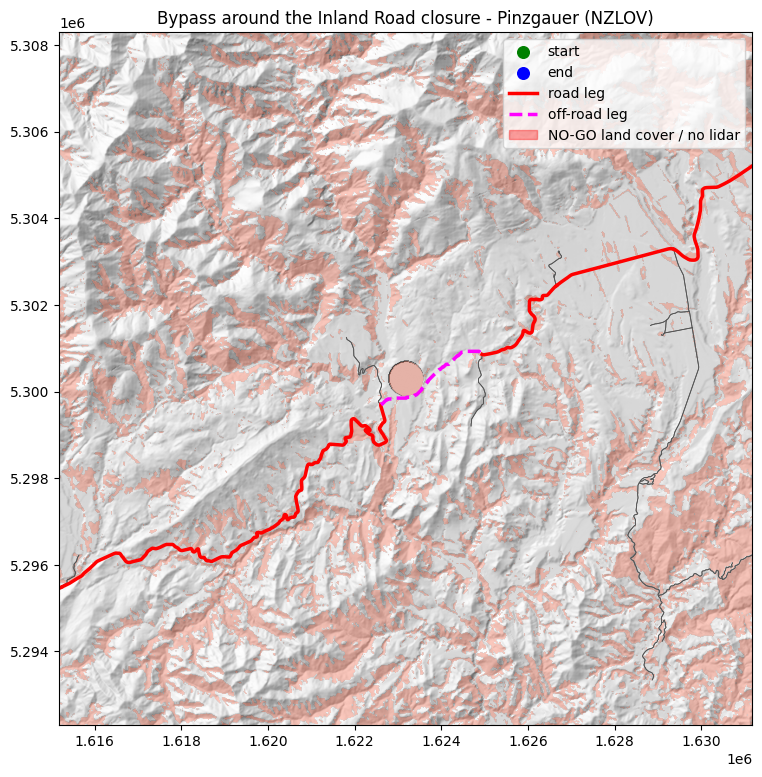

MHOV (Rheinmetall MAN HX60): 71 min (+5 min vs the open road), of which 7 min off-road


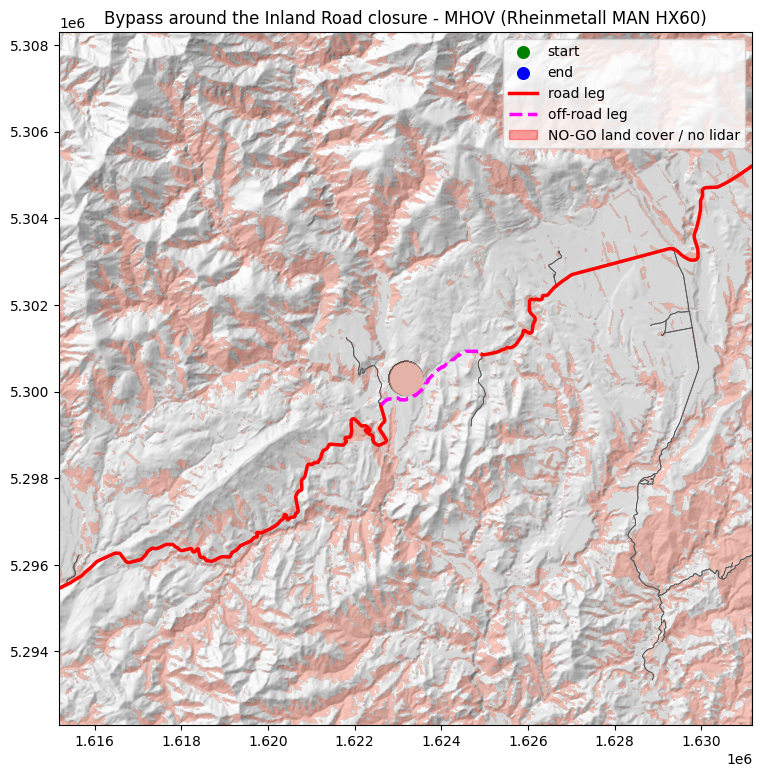

In [44]:
### Phase 2 test 3D - could an Army vehicle have driven around the Inland Road closure off-road?
"""
Scenario C cut every road into Kaikoura. Here the same SH1 slips stay blocked, and the Inland Road
closure from 3C becomes NO-GO terrain; vehicles may leave the road at the ends of the cut road
segment and drive cross-country (same cost model and SAFETY = 0.5 as before) to rejoin it.
Run for both 2016 convoy vehicles: the Pinzgauer and the MHOV truck.
"""
closure_C = pC.buffer(SLIP_RADIUS_M)
results_D = {}
_vehicle_saved, _load_terrain_saved = VEHICLE, load_terrain
try:
    ##### Terrain road cells must come from this study area's roads (G_inc), not the Phase 1 graph
    load_terrain = lambda cx, cy, half_m=None, res=None: mark_roads(_load_terrain_base(cx, cy, half_m, res), G_inc)
    for veh in ("pinzgauer", "mhov"):
        VEHICLE = veh
        G_D = G_incB.copy()                                   # SH1 slips already removed
        ##### Window big enough to hold both ends of the cut road edges (OSM rural edges can be long)
        ends = {n for u, v, k, d in G_D.edges(keys=True, data=True)
                if (d.get("geometry") or LineString([(G_D.nodes[u]["x"], G_D.nodes[u]["y"]), (G_D.nodes[v]["x"], G_D.nodes[v]["y"])])).intersects(closure_C)
                for n in (u, v)}
        reach = max(math.dist((pC.x, pC.y), (G_D.nodes[n]["x"], G_D.nodes[n]["y"])) for n in ends)
        win = min(max(WINDOW_M, reach + 1000), 15000)
        print(f"--- {VEHICLES[veh]['label']}: window half-width {win/1000:.1f} km")
        t_D, cut_D = block_and_bypass(G_D, [closure_C], window_m=win)
        try:
            r_D, c_D, _ = astar(G_D, s_inc, g_inc)
            assert math.isclose(c_D, nx.shortest_path_length(G_D, s_inc, g_inc, weight="travel_time"), rel_tol=1e-9)
            print(f"{VEHICLES[veh]['label']}: ground route found")
            tot_D, off_D = route_summary(G_D, r_D)
            results_D[veh] = (G_D, r_D, t_D, tot_D, off_D)
        except nx.NetworkXNoPath:
            print(f"{VEHICLES[veh]['label']}: no ground route even off-road - air support (helicopter) is the most likely option")
            results_D[veh] = (G_D, None, t_D, None, None)
finally:
    VEHICLE, load_terrain = _vehicle_saved, _load_terrain_saved

print(f"\nFor comparison - route B with the Inland Road open: {cB/60:.0f} min at posted speeds")
for veh, (G_D, r_D, t_D, tot_D, off_D) in results_D.items():
    if r_D is not None:
        print(f"{VEHICLES[veh]['label']}: {tot_D/60:.0f} min ({(tot_D - cB)/60:+.0f} min vs the open road), "
              f"of which {off_D/60:.0f} min off-road")
        plot_offroad(G_D, r_D, t_D, f"Bypass around the Inland Road closure - {VEHICLES[veh]['label']}",
                     f"bypass_inland_{veh}.png")


## Risk mitigations (added cells - every cell above is unchanged)

Each cell below is one mitigation from the rescue-risk review, headed `### Risk mitigation N - ...`. They only add new functions or wrap earlier ones from a new cell; nothing above is edited. Where a cell changes how an earlier function behaves (by wrapping it), it says so in a `### Changed for Risk mitigation N from ... to ... to allow for ...` comment.

| # | Risk | Mitigation |
|---|---|---|
| 1 | A road wrongly marked "open" sends a convoy into a slip | Confidence-aware cost: `t + LAMBDA * p * T_FAIL`, drop roads with `p > P_DROP` |
| 2 | Fastest is not safest | Hazard per road from nearby slope; three routes: fastest, balanced, safest |
| 3 | One-off snapshot | `replan()` re-routes as reports arrive and explains what changed |
| 4 | Bridges and weight limits invisible | Bridges get a higher blocked probability; `maxweight` below the vehicle's mass closes the road |
| 5 | Needs the internet | Offline cache for terrain and road graphs |
| 6 | Posted speeds too fast | Damaged-road speed factor calibrated on the 2016 convoy |
| 7 | Rivers not modelled | OSM rivers and streams with an assumed depth vs the vehicle's fording limit |
| 8 | Isolated communities and private tracks dropped | Full road network with isolated pockets reported and private roads flagged |
| 9 | Snapping across a river or slip | Snap to the nearest node that can actually reach the other end, with a distance warning |
| 10 | Hard-edged slip circles | Caution ring around each slip, for roads and for off-road terrain |
| 11 | Air support is only a message | Simple helicopter time estimate to compare with ground |
| 12 | Results depend on cell run order | `rescue_route()` - one call that runs everything in the right order with explicit inputs |

**All numbers marked "guess" are placeholders** to be replaced with real values (the team's blocked-road probabilities, NZDF vehicle data, river depths).


In [45]:
### Risk mitigation 1 - confidence-aware routing (a road that might be blocked costs more)
"""
Each road gets an expected cost instead of only its travel time:

    rcost = t + LAMBDA * p * T_FAIL_S          (roads with p > P_DROP are removed)

  t        = travel time on the road (s)
  p        = probability the road is blocked (0-1) - from the team's classifier when it arrives
  T_FAIL_S = time lost if the vehicle finds it blocked: drive there, turn back, detour (s)
  LAMBDA   = caution (1 = neutral, above 1 = cautious)

rcost is never below t, so astar()'s heuristic (straight line / top speed) stays admissible.
Until the team's map arrives, p is a PLACEHOLDER: P_BASE everywhere, P_NEAR_SLIP near known slips.
"""
from shapely.ops import unary_union

P_BASE = 0.02          # guess: any road just after a big quake
P_NEAR_SLIP = 0.5      # guess: road within NEAR_SLIP_M of a known slip
NEAR_SLIP_M = 1000     # guess
P_DROP = 0.8           # treat as blocked above this
LAMBDA = 2.0           # guess: cautious
T_FAIL_S = 3600        # guess: one hour lost when a road turns out to be blocked


##### Edge geometry, or a straight line between its nodes
def edge_geom(G, u, v, d):
    """Edge geometry, or a straight line between its nodes."""
    return d.get("geometry") or LineString([(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])


##### Set d["p_block"] on every edge (in place)
def set_block_probabilities(G, p_by_edge=None, slips=(), p_base=None, p_near=None, near_m=None):
    """
    Set d["p_block"] on every edge (in place).

    Args:
        p_by_edge: {(u, v, k): p} from the team's classifier; overrides the placeholders.
        slips: known slip polygons (NZTM); roads within near_m of them get p_near.
    """
    p_base = P_BASE if p_base is None else p_base
    p_near = P_NEAR_SLIP if p_near is None else p_near
    near_m = NEAR_SLIP_M if near_m is None else near_m
    zone = unary_union([s.buffer(near_m) for s in slips]) if len(slips) else None
    for u, v, k, d in G.edges(keys=True, data=True):
        if d.get("offroad"):
            d["p_block"] = 0.0                     # off-road legs are already priced by the terrain model
            continue
        p = p_base
        if zone is not None and edge_geom(G, u, v, d).intersects(zone):
            p = max(p, p_near)
        if p_by_edge and (u, v, k) in p_by_edge:
            p = float(p_by_edge[(u, v, k)])
        d["p_block"] = float(p)


##### Write d[weight] = t + lam * p * t_fail on every edge and remove edges with p > p_drop
def apply_risk_cost(G, lam=None, t_fail=None, p_drop=None, weight="rcost"):
    """Write d[weight] = t + lam * p * t_fail on every edge and remove edges with p > p_drop. Returns edges removed."""
    lam = LAMBDA if lam is None else lam
    t_fail = T_FAIL_S if t_fail is None else t_fail
    p_drop = P_DROP if p_drop is None else p_drop
    drop = []
    for u, v, k, d in G.edges(keys=True, data=True):
        p = d.get("p_block", 0.0)
        if p > p_drop:
            drop.append((u, v, k))
        else:
            d[weight] = d["travel_time"] + lam * p * t_fail
    G.remove_edges_from(drop)
    return len(drop)


##### (travel time s, expected delay s, worst p) along a route, using the cheapest parallel edge by `weight`
def route_cost_breakdown(G, route, weight="rcost"):
    """(travel time s, expected delay s, worst p) along a route, using the cheapest parallel edge by `weight`."""
    t = extra = worst = 0.0
    for a, b in zip(route[:-1], route[1:]):
        d = min(G[a][b].values(), key=lambda e: e.get(weight, math.inf))
        t += d["travel_time"]; extra += d.get(weight, d["travel_time"]) - d["travel_time"]
        worst = max(worst, d.get("p_block", 0.0))
    return t, extra, worst


##### Self-test: a short road with p = 0.5 loses to a longer safe road
def _rm1_selftest():
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    for n, (x, y) in {0: (0, 0), 1: (5000, 0), 2: (2500, 3000)}.items():
        T.add_node(n, x=x, y=y)
    T.add_edge(0, 1, travel_time=600, length=5000, speed_kph=30)          # short but probably blocked
    T.add_edge(0, 2, travel_time=750, length=4000, speed_kph=19.2)        # longer detour, safe
    T.add_edge(2, 1, travel_time=750, length=4000, speed_kph=19.2)
    set_block_probabilities(T, p_by_edge={(0, 1, 0): 0.5})
    apply_risk_cost(T)
    r_fast, _, _ = astar(T, 0, 1, weight="travel_time")
    r_safe, c_safe, _ = astar(T, 0, 1, weight="rcost")
    assert r_fast == [0, 1] and r_safe == [0, 2, 1], (r_fast, r_safe)
    assert math.isclose(c_safe, 1500 + 2 * LAMBDA * P_BASE * T_FAIL_S)
    print(f"RM1 self-test passed: 50%-risk short road (10 min) loses to a safe 25 min detour")

_rm1_selftest()

##### On the 2016 scenario (needs test 3 above): SH1 slips known, placeholder probabilities
if "G_incB" in globals():
    G_rm1 = G_incB.copy()
    set_block_probabilities(G_rm1, slips=INC_BLOCKAGES)
    n_drop = apply_risk_cost(G_rm1)
    r1, c1, _ = astar(G_rm1, s_inc, g_inc, weight="rcost")
    t1, x1, w1 = route_cost_breakdown(G_rm1, r1)
    print(f"2016 scenario: {n_drop} roads dropped (p > {P_DROP}); route {t1/60:.0f} min driving "
          f"+ {x1/60:.0f} min expected delay, worst road p = {w1:.2f}")


RM1 self-test passed: 50%-risk short road (10 min) loses to a safe 25 min detour
2016 scenario: 0 roads dropped (p > 0.8); route 73 min driving + 175 min expected delay, worst road p = 0.02


In [46]:
### Risk mitigation 2 - hazard layer and three route choices (fastest, balanced, safest)
"""
Hazard h (0-1) for each road = how steep the ground beside it is (rockfall / slip exposure):

    h = clip((S - S_LOW) / (S_HIGH - S_LOW), 0, 1)

  S              = steepest slope (deg) within HAZARD_RADIUS_M of points every HAZARD_STEP_M along the road,
                   from a coarse HAZARD_RES_M elevation grid (same data sources as the off-road model)
  S_LOW, S_HIGH  = slope where hazard starts / is treated as maximum (guesses)

Three route costs, all >= travel time so astar() stays admissible:

    fastest  = t
    balanced = rcost * (1 + KAPPA_BAL * h)
    safest   = rcost * (1 + KAPPA_SAFE * h)

  t     = travel time (s);  rcost = confidence-aware cost from Risk mitigation 1 (s)
  KAPPA = how much a fully hazardous road is penalised (KAPPA = 2 makes it count as 3x as long)
The commander picks; the model shows the trade-off.
"""
from scipy.ndimage import maximum_filter

HAZARD_RES_M = 100       # coarse grid is enough for "is there a steep slope beside this road"
HAZARD_RADIUS_M = 200    # guess
HAZARD_STEP_M = 250
S_LOW, S_HIGH = 25.0, 45.0   # guesses (deg)
KAPPA_BAL, KAPPA_SAFE = 1.0, 5.0


##### Set d["hazard"] (0-1) on every edge of G (in place)
def compute_hazard(G, res=None, radius=None, step=None):
    """Set d["hazard"] (0-1) on every edge of G (in place); off-road legs get 0 (slope is already in their cost)."""
    res, radius, step = res or HAZARD_RES_M, radius or HAZARD_RADIUS_M, step or HAZARD_STEP_M
    xs = [d["x"] for _, d in G.nodes(data=True)]; ys = [d["y"] for _, d in G.nodes(data=True)]
    pad = radius + 2 * res
    xmin = math.floor((min(xs) - pad) / res) * res; ymax = math.ceil((max(ys) + pad) / res) * res
    cols = int(math.ceil((max(xs) + pad - xmin) / res)); rows = int(math.ceil((ymax - (min(ys) - pad)) / res))
    bounds = (xmin, ymax - rows * res, xmin + cols * res, ymax)
    dem = load_dem(bounds, res)
    gy, gx = np.gradient(dem, res)
    slope = np.nan_to_num(np.degrees(np.arctan(np.hypot(gx, gy))), nan=0.0)
    smax = maximum_filter(slope, size=2 * int(radius // res) + 1)
    inv = ~from_origin(bounds[0], bounds[3], res, res)
    for u, v, k, d in G.edges(keys=True, data=True):
        if d.get("offroad"):
            d["hazard"] = 0.0
            continue
        geom = edge_geom(G, u, v, d)
        S = 0.0
        for s in list(np.arange(0, geom.length, step)) + [geom.length]:
            p = geom.interpolate(s)
            c, r = inv * (p.x, p.y)
            r, c = int(r), int(c)
            if 0 <= r < rows and 0 <= c < cols:
                S = max(S, smax[r, c])
        d["hazard"] = float(np.clip((S - S_LOW) / (S_HIGH - S_LOW), 0, 1))
        d["max_slope_deg"] = float(S)
    return smax


##### Write 'w_fastest', 'w_balanced', 'w_safest' on every edge (needs rcost from RM1 and hazard)
def set_route_weights(G):
    """Write 'w_fastest', 'w_balanced', 'w_safest' on every edge (needs rcost from RM1 and hazard)."""
    for _, _, d in G.edges(data=True):
        base = d.get("rcost", d["travel_time"])
        h = d.get("hazard", 0.0)
        d["w_fastest"] = d["travel_time"]
        d["w_balanced"] = base * (1 + KAPPA_BAL * h)
        d["w_safest"] = base * (1 + KAPPA_SAFE * h)


##### (length-weighted mean hazard, max hazard) along a route
def route_hazard(G, route, weight):
    """(length-weighted mean hazard, max hazard) along a route."""
    L = H = mx = 0.0
    for a, b in zip(route[:-1], route[1:]):
        d = min(G[a][b].values(), key=lambda e: e.get(weight, math.inf))
        L += d["length"]; H += d["length"] * d.get("hazard", 0.0); mx = max(mx, d.get("hazard", 0.0))
    return (H / L if L else 0.0), mx


##### Fastest, balanced and safest routes
def three_routes(G, src, dst):
    """Fastest, balanced and safest routes; prints a comparison table. Returns {name: route or None}."""
    set_route_weights(G)
    out = {}
    print(f"{'route':9s} {'drive min':>9s} {'exp. delay':>10s} {'mean haz':>8s} {'max haz':>7s}")
    for name in ("fastest", "balanced", "safest"):
        try:
            r, _, _ = astar(G, src, dst, weight=f"w_{name}")
        except nx.NetworkXNoPath:
            print(f"{name:9s} no route"); out[name] = None; continue
        t = x = 0.0
        for a, b in zip(r[:-1], r[1:]):
            d = min(G[a][b].values(), key=lambda e: e.get(f"w_{name}", math.inf))
            t += d["travel_time"]; x += d.get("rcost", d["travel_time"]) - d["travel_time"]   # expected delay from RM1
        mh, xh = route_hazard(G, r, f"w_{name}")
        print(f"{name:9s} {t/60:9.0f} {x/60:10.0f} {mh:8.2f} {xh:7.2f}")
        out[name] = r
    return out


##### Self-test: a hazardous short road vs a safe long road
def _rm2_selftest():
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    for n, (x, y) in {0: (0, 0), 1: (5000, 0), 2: (2500, 2000)}.items():
        T.add_node(n, x=x, y=y)
    T.add_edge(0, 1, travel_time=600, length=5000, speed_kph=30, hazard=1.0)
    T.add_edge(0, 2, travel_time=500, length=3200, speed_kph=23, hazard=0.0)
    T.add_edge(2, 1, travel_time=500, length=3200, speed_kph=23, hazard=0.0)
    set_block_probabilities(T); apply_risk_cost(T, p_drop=1.0); set_route_weights(T)
    assert astar(T, 0, 1, weight="w_fastest")[0] == [0, 1]
    assert astar(T, 0, 1, weight="w_safest")[0] == [0, 2, 1]
    print("RM2 self-test passed: the safest route avoids a fully hazardous road, the fastest does not")

_rm2_selftest()

##### On the 2016 scenario (needs RM1's G_rm1): hazard from slopes beside each road
if "G_rm1" in globals():
    compute_hazard(G_rm1)
    hz = [d["hazard"] for _, _, d in G_rm1.edges(data=True)]
    print(f"Hazard computed for {len(hz)} roads; {np.mean(np.array(hz) > 0.5):.0%} have h > 0.5")
    routes_rm2 = three_routes(G_rm1, s_inc, g_inc)


RM2 self-test passed: the safest route avoids a fully hazardous road, the fastest does not
DEM sources: Kaikoura 2016-17 lidar 15%, national 1 m 57%, national 8 m 0%, none 28%
Hazard computed for 7572 roads; 1% have h > 0.5
route     drive min exp. delay mean haz max haz
fastest          66        194     0.08    0.31
balanced         73        175     0.06    0.31
safest           73        175     0.06    0.31


In [47]:
### Risk mitigation 3 - re-plan as reports arrive, and explain what changed
"""
Roads open and close by the hour. replan() rebuilds the blocked probabilities from ALL reports so far
(the latest report for a road wins), re-routes, and explains the change against the previous route.

A report is a dict: {"time": "18 Nov 10:00", "area": NZTM polygon, "p": 0-1, "note": "..."}
  p = 1.0 closed, about 0.9 slip risk / turned back, about 0.1 reopened under control
"""


##### Route on a copy of G_base given every report so far
def replan(G_base, src, dst, reports, prev_route=None, weight="rcost"):
    """
    Route on a copy of G_base given every report so far. Prints the route and why it differs from prev_route.

    Returns:
        (route or None, graph used).
    """
    Gp = G_base.copy()
    set_block_probabilities(Gp)                               # placeholder baseline everywhere
    for rep in reports:                                       # later reports overwrite earlier ones
        for u, v, k, d in Gp.edges(keys=True, data=True):
            if not d.get("offroad") and edge_geom(Gp, u, v, d).intersects(rep["area"]):
                d["p_block"] = float(rep["p"])
    apply_risk_cost(Gp)
    last = reports[-1] if reports else {"time": "start", "note": "no reports"}
    try:
        r, c, _ = astar(Gp, src, dst, weight=weight)
    except nx.NetworkXNoPath:
        print(f"[{last['time']}] {last['note']}: NO GROUND ROUTE - air support (helicopter) is the most likely option")
        return None, Gp
    t, x, worst = route_cost_breakdown(Gp, r, weight)
    msg = f"[{last['time']}] {last['note']}: route {t/60:.0f} min (+{x/60:.0f} min expected delay), worst road p = {worst:.2f}"
    if prev_route is None:
        msg += " - first plan"
    elif r == prev_route:
        msg += " - unchanged"
    else:
        old, new = set(zip(prev_route[:-1], prev_route[1:])), set(zip(r[:-1], r[1:]))
        msg += f" - CHANGED: {len(old - new)} road segments dropped, {len(new - old)} added"
    print(msg)
    return r, Gp


##### Self-test: close the direct road, then reopen it
def _rm3_selftest():
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    for n, (x, y) in {0: (0, 0), 1: (5000, 0), 2: (2500, 3000)}.items():
        T.add_node(n, x=x, y=y)
    for a, b, tt in ((0, 1, 600), (0, 2, 900), (2, 1, 900)):
        T.add_edge(a, b, travel_time=tt, length=tt * 8, speed_kph=28.8)
    slip = Point(2500, 0).buffer(100)
    r0, _ = replan(T, 0, 1, [])
    r1, _ = replan(T, 0, 1, [{"time": "t1", "area": slip, "p": 1.0, "note": "slip on direct road"}], r0)
    r2, _ = replan(T, 0, 1, [{"time": "t1", "area": slip, "p": 1.0, "note": "slip"},
                             {"time": "t2", "area": slip, "p": 0.05, "note": "reopened"}], r1)
    assert r0 == [0, 1] and r1 == [0, 2, 1] and r2 == [0, 1]
    print("RM3 self-test passed")

_rm3_selftest()

##### 2016 replay (needs test 3 above): the reports in the order they came in
if "G_inc" in globals() and "pC" in globals():
    print("\n2016 replay - Culverden to Kaikoura (Inland Road closure point is the 3C stand-in; probabilities illustrative):")
    rep_2016 = [
        {"time": "14 Nov", "area": unary_union(INC_BLOCKAGES), "p": 1.0, "note": "SH1 cut by slips north and south"},
        {"time": "18 Nov am", "area": pC.buffer(SLIP_RADIUS_M), "p": 0.5, "note": "Inland Road: slip risk reported"},
        {"time": "18 Nov pm", "area": pC.buffer(SLIP_RADIUS_M), "p": 0.95, "note": "Inland Road: convoy turned back"},
        {"time": "21 Nov", "area": pC.buffer(SLIP_RADIUS_M), "p": 0.1, "note": "Inland Road: controlled access"},
    ]
    prev = None
    for i in range(len(rep_2016) + 1):
        r_rep, _ = replan(G_inc, s_inc, g_inc, rep_2016[:i], prev)
        prev = r_rep or prev


[start] no reports: route 10 min (+2 min expected delay), worst road p = 0.02 - first plan
[t1] slip on direct road: route 30 min (+5 min expected delay), worst road p = 0.02 - CHANGED: 1 road segments dropped, 2 added
[t2] reopened: route 10 min (+6 min expected delay), worst road p = 0.05 - CHANGED: 2 road segments dropped, 1 added
RM3 self-test passed

2016 replay - Culverden to Kaikoura (Inland Road closure point is the 3C stand-in; probabilities illustrative):
[start] no reports: route 73 min (+175 min expected delay), worst road p = 0.02 - first plan
[14 Nov] SH1 cut by slips north and south: route 73 min (+175 min expected delay), worst road p = 0.02 - unchanged
[18 Nov am] Inland Road: slip risk reported: route 73 min (+233 min expected delay), worst road p = 0.50 - unchanged
[18 Nov pm] Inland Road: convoy turned back: NO GROUND ROUTE - air support (helicopter) is the most likely option
[21 Nov] Inland Road: controlled access: route 73 min (+185 min expected delay), worst road

In [48]:
### Risk mitigation 4 - bridges and weight limits
"""
After a big quake every bridge is suspect until inspected, and heavy trucks cannot use light bridges.
  - Roads tagged bridge in OpenStreetMap get p_block raised to at least BRIDGE_P (Risk mitigation 1 cost).
  - Roads with a maxweight (tonnes) below the vehicle's mass are closed for that vehicle (p_block = 1).
Phase 1 already asks OSM for the 'bridge' and 'maxweight' tags (useful_tags_way in build_graph).
"""
import re

BRIDGE_P = 0.3                                     # guess: uninspected bridge after a major quake
VEHICLE_MASS_T = {"pinzgauer": 4.5, "mhov": 16.0}  # guesses - replace with NZDF gross vehicle masses


##### OSM tags can be a value or a list (after simplification)
def _tag_values(x):
    """OSM tags can be a value or a list (after simplification); return a list of strings."""
    return [str(v) for v in (x if isinstance(x, list) else [x]) if v is not None and str(v) != "nan"]


##### Smallest maxweight in tonnes from an OSM value like '10', '10 t', '3.5'
def _maxweight_t(x):
    """Smallest maxweight in tonnes from an OSM value like '10', '10 t', '3.5'; None if not parseable."""
    vals = []
    for s in _tag_values(x):
        m = re.match(r"\s*([0-9]+(?:\.[0-9]+)?)\s*(t|tonnes?)?\s*$", s.lower())
        if m:
            vals.append(float(m.group(1)))
    return min(vals) if vals else None


##### Raise p_block on bridges and close roads below the vehicle's mass (in place)
def apply_bridge_rules(G, vehicle=None, bridge_p=None):
    """Raise p_block on bridges and close roads below the vehicle's mass (in place). Returns (bridges, closed)."""
    vehicle = vehicle or VEHICLE
    bridge_p = BRIDGE_P if bridge_p is None else bridge_p
    mass = VEHICLE_MASS_T[vehicle]
    nb = nc = 0
    for _, _, d in G.edges(data=True):
        if d.get("offroad"):
            continue
        if any(v.lower() not in ("no", "false") for v in _tag_values(d.get("bridge"))):
            d["p_block"] = max(d.get("p_block", 0.0), bridge_p); d["is_bridge"] = True; nb += 1
        mw = _maxweight_t(d.get("maxweight"))
        if mw is not None and mw < mass:
            d["p_block"] = 1.0; d["weight_closed"] = True; nc += 1
    return nb, nc


##### Self-test
def _rm4_selftest():
    assert _maxweight_t("10 t") == 10.0 and _maxweight_t(["3.5", "12"]) == 3.5 and _maxweight_t("10 st") is None
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    T.add_node(0, x=0, y=0); T.add_node(1, x=100, y=0)
    T.add_edge(0, 1, travel_time=10, length=100, speed_kph=36, bridge="yes", maxweight="10")
    set_block_probabilities(T)
    assert apply_bridge_rules(T, "pinzgauer") == (1, 0) and T[0][1][0]["p_block"] == BRIDGE_P
    set_block_probabilities(T)
    assert apply_bridge_rules(T, "mhov") == (1, 1) and T[0][1][0]["p_block"] == 1.0
    print("RM4 self-test passed: bridge flagged; 10 t bridge closed to the MHOV, open to the Pinzgauer")

_rm4_selftest()

##### On the 2016 study area (needs test 3 above)
if "G_inc" in globals():
    for veh in ("pinzgauer", "mhov"):
        G_rm4 = G_incB.copy()
        set_block_probabilities(G_rm4, slips=INC_BLOCKAGES)
        nb, nc = apply_bridge_rules(G_rm4, veh)
        apply_risk_cost(G_rm4)
        try:
            r4, _, _ = astar(G_rm4, s_inc, g_inc, weight="rcost")
            t4, x4, w4 = route_cost_breakdown(G_rm4, r4)
            nbr = sum(1 for a, b in zip(r4[:-1], r4[1:]) if min(G_rm4[a][b].values(), key=lambda e: e["rcost"]).get("is_bridge"))
            print(f"{VEHICLES[veh]['label']}: {nb} bridge segments flagged, {nc} closed by weight; "
                  f"route crosses {nbr} bridge segments, {t4/60:.0f} min + {x4/60:.0f} min expected delay")
        except nx.NetworkXNoPath:
            print(f"{VEHICLES[veh]['label']}: no route once weight limits apply - air support most likely")


RM4 self-test passed: bridge flagged; 10 t bridge closed to the MHOV, open to the Pinzgauer
Pinzgauer (NZLOV): 316 bridge segments flagged, 0 closed by weight; route crosses 13 bridge segments, 75 min + 612 min expected delay
MHOV (Rheinmetall MAN HX60): 316 bridge segments flagged, 0 closed by weight; route crosses 13 bridge segments, 75 min + 612 min expected delay


In [49]:
### Risk mitigation 5 - offline mode (pre-download terrain and roads before an event)
"""
Cell towers may be down in a real event. Terrain windows and road graphs are saved to OFFLINE_DIR the
first time they are loaded; after that they load from disk with no internet.
Point OFFLINE_DIR at Google Drive (mount it first) to keep the cache between Colab sessions.
"""
OFFLINE_DIR = "/content/offline_cache"
os.makedirs(OFFLINE_DIR, exist_ok=True)

### Changed for Risk mitigation 5 from _load_terrain_base (downloads every time) to a cached version
### to allow for running without internet once an area has been pre-fetched. (Earlier cells are not edited;
### this cell re-points the name, and every later terrain load goes through the cache.)
if "_rm5_online_terrain" not in globals():
    _rm5_online_terrain = _load_terrain_base          # the downloading loader (cell "Phase 2 data")


##### Terrain window from OFFLINE_DIR if cached there, otherwise download and cache it
def _load_terrain_base(cx, cy, half_m=None, res=None):
    """Terrain window from OFFLINE_DIR if cached there, otherwise download and cache it."""
    half_m, res = half_m or WINDOW_M, res or RES_M
    transform, shape, bounds = make_grid(cx, cy, half_m, res)
    path = os.path.join(OFFLINE_DIR, "terrain_" + "_".join(str(int(b)) for b in bounds) + f"_{res}.npz")
    if os.path.exists(path):
        z = np.load(path)
        print(f"Terrain {shape[1]}x{shape[0]} cells @ {res} m loaded offline from {os.path.basename(path)}")
        return {"transform": transform, "shape": shape, "bounds": bounds, "res": res,
                "dem": z["dem"].copy(), "lc": z["lc"].copy()}
    t = _rm5_online_terrain(cx, cy, half_m, res)
    np.savez_compressed(path, dem=t["dem"], lc=t["lc"])
    return t


##### Road graph for a WGS84 polygon via Phase 1 build_graph(), saved as GraphML in OFFLINE_DIR
def cached_graph(poly_wgs84, name):
    """Road graph for a WGS84 polygon via Phase 1 build_graph(), saved as GraphML in OFFLINE_DIR."""
    path = os.path.join(OFFLINE_DIR, f"graph_{name}.graphml")
    if os.path.exists(path):
        print(f"Road graph '{name}' loaded offline")
        return ox.load_graphml(path)
    Gc = build_graph(poly_wgs84)
    ox.save_graphml(Gc, path)
    return Gc


##### Download and cache terrain windows around each (lon, lat) so they work offline later
def prefetch_offline(points_lonlat, half_m=None):
    """Download and cache terrain windows around each (lon, lat) so they work offline later."""
    tr = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True)
    for lon, lat in points_lonlat:
        _load_terrain_base(*tr.transform(lon, lat), half_m)


##### Self-test: second load of the same window comes from disk and matches
def _rm5_selftest():
    import time
    x, y = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*START_LONLAT)
    t0 = time.time(); a = _load_terrain_base(x, y, 1000); t1 = time.time()
    b = _load_terrain_base(x, y, 1000); t2 = time.time()
    assert np.array_equal(np.nan_to_num(a["dem"], nan=-1), np.nan_to_num(b["dem"], nan=-1)) and np.array_equal(a["lc"], b["lc"])
    print(f"RM5 self-test passed: first load {t1 - t0:.1f} s (download), second {t2 - t1:.2f} s (offline)")

_rm5_selftest()


DEM sources: Kaikoura 2016-17 lidar 65%, national 1 m 24%, national 8 m 0%, none 11%
Terrain 100x100 cells @ 20 m | lidar coverage 89% | land cover coverage 100%
Terrain 100x100 cells @ 20 m loaded offline from terrain_1655040_5304260_1657040_5306260_20.npz
RM5 self-test passed: first load 1.1 s (download), second 0.00 s (offline)


In [50]:
### Risk mitigation 6 - realistic road speeds after a quake (calibrated on the 2016 convoy)
"""
Posted speed limits are far faster than a convoy on damaged roads. The real convoy took about 240 min
for the route the model drives in about 66 min at posted speeds (test 3B), a factor of about 3.7.

    t_damaged = t_posted * F

  t_posted = road travel time at posted speeds (s);  F = slow-down factor for that road class

The factor matters because it changes the balance between road and off-road legs (off-road speeds are
already terrain-based). DAMAGE_FACTOR_BY_CLASS lets you set different factors per OSM highway class.
"""
CONVOY_CALIBRATION = 3.7         # checked: 240 min real vs about 66 min modelled (test 3B)
DAMAGE_FACTOR_DEFAULT = CONVOY_CALIBRATION
DAMAGE_FACTOR_BY_CLASS = {}      # e.g. {"primary": 3.0, "track": 1.5} - guesses to fill in


##### Return a copy of G with road (not off-road) travel times multiplied by the damage factor
def apply_damage_speeds(G, default=None, by_class=None):
    """Return a copy of G with road (not off-road) travel times multiplied by the damage factor."""
    default = DAMAGE_FACTOR_DEFAULT if default is None else default
    by_class = DAMAGE_FACTOR_BY_CLASS if by_class is None else by_class
    Gd = G.copy()
    for _, _, d in Gd.edges(data=True):
        if d.get("offroad"):
            continue
        hw = d.get("highway"); hw = hw[0] if isinstance(hw, list) else hw
        f = by_class.get(hw, default)
        d["travel_time"] *= f
        d["speed_kph"] /= f
    return Gd


##### Self-test
def _rm6_selftest():
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    T.add_node(0, x=0, y=0); T.add_node(1, x=1000, y=0)
    T.add_edge(0, 1, travel_time=36, length=1000, speed_kph=100, highway="primary")
    T.add_edge(0, 1, travel_time=150, length=1000, speed_kph=24, highway="offroad", offroad=True)
    assert astar(T, 0, 1)[1] == 36
    assert math.isclose(astar(apply_damage_speeds(T, default=5), 0, 1)[1], 150)   # off-road now wins
    print("RM6 self-test passed: slowing damaged roads can flip the choice to the off-road leg")

_rm6_selftest()

##### On the 2016 bypass (needs test 3D above): does the off-road share change at calibrated speeds?
if "results_D" in globals() and results_D.get("pinzgauer", (None, None))[1] is not None:
    G_D0 = results_D["pinzgauer"][0]
    for label, Gx in (("posted speeds", G_D0), (f"calibrated x{CONVOY_CALIBRATION}", apply_damage_speeds(G_D0))):
        rx, cx, _ = astar(Gx, s_inc, g_inc)
        print(f"{label}: ", end=""); route_summary(Gx, rx)


RM6 self-test passed: slowing damaged roads can flip the choice to the off-road leg
posted speeds:   road: 100.99 km, 63.9 min | off-road: 2.91 km, 6.5 min | total 70.4 min
calibrated x3.7:   road: 95.12 km, 223.3 min | off-road: 8.39 km, 18.9 min | total 242.1 min


In [51]:
### Risk mitigation 7 - rivers and fording limits
"""
Braided gravel rivers (Waiau, Conway, Clarence) show up in land cover as passable bare ground. Here
OpenStreetMap rivers and streams are burned into each terrain window with an ASSUMED depth, and a cell
is NO-GO for a vehicle whose fording limit is below that depth. Road cells (bridges, fords) stay open.

  RIVER_DEPTH_M / STREAM_DEPTH_M = assumed water depth (guesses; replace with gauge or survey data)
  FORD_M = vehicle fording limit, unprepared (checked earlier: Pinzgauer 0.70 m, HX range 0.75 m - Wikipedia)
"""
RIVER_DEPTH_M = 1.0              # guess
STREAM_DEPTH_M = 0.3             # guess
RIVER_WIDTH_M = 40               # guess: buffer for rivers mapped only as a centre line
FORD_M = {"pinzgauer": 0.70, "mhov": 0.75}


##### Assumed water depth (m) per cell from OSM waterways inside the terrain window
def river_depth_grid(t):
    """Assumed water depth (m) per cell from OSM waterways inside the terrain window; 0 = dry."""
    from rasterio.features import rasterize
    from rasterio.enums import MergeAlg
    w, s, e, n = transform_bounds(CRS_NZTM, "EPSG:4326", *t["bounds"])
    try:
        f = ox.features_from_bbox((w, s, e, n), tags={"waterway": ["river", "stream"], "water": ["river"]})
    except Exception as ex:                       # no features, or no internet
        print(f"River layer: none loaded ({type(ex).__name__})")
        return np.zeros(t["shape"])
    f = f.to_crs(CRS_NZTM)
    shapes = []
    for _, row in f.iterrows():
        g = row.geometry
        ww = row.get("waterway") if "waterway" in f.columns else None
        if g.geom_type in ("LineString", "MultiLineString"):
            depth = RIVER_DEPTH_M if ww == "river" else STREAM_DEPTH_M
            g = g.buffer(RIVER_WIDTH_M / 2 if ww == "river" else t["res"] / 2)
        else:
            depth = RIVER_DEPTH_M
        shapes.append((g, depth))
    if not shapes:
        return np.zeros(t["shape"])
    return rasterize(shapes, out_shape=t["shape"], transform=t["transform"], all_touched=True,
                     fill=0.0, dtype="float32", merge_alg=MergeAlg.replace)


### Changed for Risk mitigation 7 from _load_terrain_base (no rivers) to one that also stores
### t["river_depth"] to allow for fording limits (the river layer is cached offline like the terrain).
if "_rm7_terrain_no_rivers" not in globals():
    _rm7_terrain_no_rivers = _load_terrain_base

##### Terrain window (cached, Risk mitigation 5) plus an assumed river depth grid
def _load_terrain_base(cx, cy, half_m=None, res=None):
    """Terrain window (cached, Risk mitigation 5) plus an assumed river depth grid."""
    t = _rm7_terrain_no_rivers(cx, cy, half_m, res)
    path = os.path.join(OFFLINE_DIR, "rivers_" + "_".join(str(int(b)) for b in t["bounds"]) + f"_{t['res']}.npy")
    if os.path.exists(path):
        t["river_depth"] = np.load(path)
    else:
        t["river_depth"] = river_depth_grid(t)
        np.save(path, t["river_depth"])
    print(f"River layer: {(t['river_depth'] > 0).mean():.1%} of cells are mapped water")
    return t


### Changed for Risk mitigation 7 from build_offroad_graph (cell "Phase 2 linking fixes") to a version that
### makes river cells deeper than the vehicle's fording limit NO-GO, to allow for fording limits.
if "_rm7_build_no_rivers" not in globals():
    _rm7_build_no_rivers = build_offroad_graph

##### Off-road grid graph with river cells deeper than FORD_M[vehicle] removed (road cells stay open)
def build_offroad_graph(t, vehicle=None, lc_speed=None):
    """Off-road grid graph with river cells deeper than FORD_M[vehicle] removed (road cells stay open)."""
    depth = t.get("river_depth")
    if depth is None:
        return _rm7_build_no_rivers(t, vehicle, lc_speed)
    too_deep = depth > FORD_M[vehicle or VEHICLE]
    road = t.get("road")
    if road is not None:
        too_deep &= ~road
    t2 = dict(t); t2["dem"] = t["dem"].copy(); t2["dem"][too_deep] = np.nan
    return _rm7_build_no_rivers(t2, vehicle, lc_speed)


##### Self-test: a 1 m deep river blocks both vehicles; a 0.5 m one does not
def _rm7_selftest():
    t = _synthetic(np.zeros((5, 60)))
    t["river_depth"] = np.zeros((5, 60)); t["river_depth"][:, 30] = 1.0
    a, b = 2 * 60 + 5, 2 * 60 + 55
    assert not np.isfinite(dijkstra(build_offroad_graph(t, "pinzgauer"), indices=a)[b])
    t["river_depth"][:, 30] = 0.5
    assert np.isfinite(dijkstra(build_offroad_graph(t, "pinzgauer"), indices=a)[b])
    print("RM7 self-test passed: 1.0 m river is NO-GO, 0.5 m river can be forded")

_rm7_selftest()


RM7 self-test passed: 1.0 m river is NO-GO, 0.5 m river can be forded


In [52]:
### Risk mitigation 8 - keep isolated communities and private / farm tracks in view
"""
Phase 1 build_graph() keeps only the largest connected road network and drops private roads. In a rescue,
the dropped pockets may be exactly the cut-off communities, and farm tracks may be the way through.

build_graph_full() (new; Phase 1 build_graph is unchanged):
  - includes private / no-access roads, flagged d["permission_needed"] = True and slowed by PRIVATE_FACTOR
  - keeps every road, and isolated_pockets() reports the pieces not joined to the main network
    ("check these - they may need air or a ground team")
"""
CF_FULL = ('["highway"~"motorway|trunk|primary|secondary|tertiary|unclassified|residential|service|track"]'
           '["area"!~"yes"]')
PRIVATE_FACTOR = 1.5      # guess: gates, permission, unknown surface


##### Like Phase 1 build_graph, but keeps private roads (flagged) and every disconnected piece
def build_graph_full(poly_wgs84):
    """Like Phase 1 build_graph, but keeps private roads (flagged) and every disconnected piece."""
    Gf = ox.graph_from_polygon(poly_wgs84, custom_filter=CF_FULL, simplify=True, retain_all=True)
    Gf = ox.routing.add_edge_speeds(Gf)
    Gf = ox.routing.add_edge_travel_times(Gf)
    for _, _, d in Gf.edges(data=True):
        acc = [str(a).lower() for a in (d.get("access") if isinstance(d.get("access"), list) else [d.get("access")])]
        if any(a in ("private", "no") for a in acc):
            d["permission_needed"] = True
            d["travel_time"] *= PRIVATE_FACTOR
            d["speed_kph"] /= PRIVATE_FACTOR
    return ox.project_graph(Gf, to_crs=CRS_NZTM)


##### Road pieces not connected to the largest one: list of (n_nodes, lon, lat of centre), biggest first
def isolated_pockets(Gf, min_nodes=2):
    """Road pieces not connected to the largest one: list of (n_nodes, lon, lat of centre), biggest first."""
    comps = sorted(nx.weakly_connected_components(Gf), key=len, reverse=True)
    to_ll = Transformer.from_crs(CRS_NZTM, "EPSG:4326", always_xy=True)
    out = []
    for c in comps[1:]:
        if len(c) < min_nodes:
            continue
        x = np.mean([Gf.nodes[n]["x"] for n in c]); y = np.mean([Gf.nodes[n]["y"] for n in c])
        out.append((len(c), *to_ll.transform(x, y)))
    return out


##### Phase 1 study area: what the original graph leaves out
G_full = build_graph_full(poly)
n_priv = sum(1 for _, _, d in G_full.edges(data=True) if d.get("permission_needed"))
pockets = isolated_pockets(G_full)
print(f"Phase 1 graph G: {len(G.nodes)} nodes | full graph: {len(G_full.nodes)} nodes, "
      f"{n_priv} private/no-access road segments (flagged), {len(pockets)} isolated pockets "
      f"(some are only roads clipped by the study-area edge)")
for n, lon, lat in pockets[:10]:
    print(f"  pocket of {n} nodes near ({lon:.4f}, {lat:.4f}) - not reachable by road from the main network")


Phase 1 graph G: 869 nodes | full graph: 919 nodes, 58 private/no-access road segments (flagged), 5 isolated pockets (some are only roads clipped by the study-area edge)
  pocket of 12 nodes near (173.4757, -42.5911) - not reachable by road from the main network
  pocket of 7 nodes near (173.3656, -42.4956) - not reachable by road from the main network
  pocket of 6 nodes near (173.3973, -42.5426) - not reachable by road from the main network
  pocket of 4 nodes near (173.3542, -42.5590) - not reachable by road from the main network
  pocket of 3 nodes near (173.3916, -42.5614) - not reachable by road from the main network


In [53]:
### Risk mitigation 9 - snap to a node that can actually reach the other end, and warn on long snaps
"""
Phase 1 snap() picks the nearest node, which can sit across a river, on the wrong side of a slip, or in an
isolated pocket. snap_reachable() tries the K nearest nodes and takes the first one with a road path to
(or from) the other end, and warns when the snap distance is over SNAP_WARN_M.
"""
SNAP_WARN_M = 200
SNAP_K = 25


##### Nearest node that has a path to `other` (role="start") or from `other` (role="end")
def snap_reachable(Gs, lonlat, other, role="start", k=None, warn_m=None):
    """
    Nearest node that has a path to `other` (role="start") or from `other` (role="end").

    Returns:
        (node, distance m, note).
    """
    k, warn_m = k or SNAP_K, warn_m or SNAP_WARN_M
    x, y = Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*lonlat)
    nodes = np.array(list(Gs.nodes))
    xy = np.array([(Gs.nodes[n]["x"], Gs.nodes[n]["y"]) for n in nodes])
    dist = np.hypot(xy[:, 0] - x, xy[:, 1] - y)
    order = np.argsort(dist)[:k]
    for i, idx in enumerate(order):
        n = nodes[idx].item() if hasattr(nodes[idx], "item") else nodes[idx]
        ok = nx.has_path(Gs, n, other) if role == "start" else nx.has_path(Gs, other, n)
        if ok:
            note = []
            if i > 0:
                note.append(f"nearest {i} node(s) skipped - no road path to the other end")
            if dist[idx] > warn_m:
                note.append(f"WARNING: {dist[idx]:.0f} m from the nearest usable road - check the map")
            return n, float(dist[idx]), "; ".join(note) or "ok"
    raise nx.NetworkXNoPath(f"{role}: none of the {k} nearest nodes can reach the other end - air support most likely")


##### Self-test on the Phase 1 graph: the goal is 6 km from a road and should warn
n_end, d_end, note_end = snap_reachable(G, END_LONLAT, src, role="end")
assert d_end > SNAP_WARN_M and "WARNING" in note_end
print(f"RM9 self-test passed: goal snaps {d_end:.0f} m away -> {note_end}")
if "G_incC" in globals():
    try:
        snap_reachable(G_incC, inc_pts["goal"][:2], s_inc, role="end")
    except nx.NetworkXNoPath as ex:
        print(f"Scenario C (every road in cut): {ex}")


RM9 self-test passed: goal snaps 6158 m away -> WARNING: 6158 m from the nearest usable road - check the map
Scenario C (every road in cut): end: none of the 25 nearest nodes can reach the other end - air support most likely


In [54]:
### Risk mitigation 10 - caution ring around each slip (no hard edge)
"""
Ground next to a slip is often unstable too. Two rings:
  - Roads within ROAD_RING_M of a slip: slowed by RING_SLOW (and Risk mitigation 1 already raises their p).
  - Off-road: the NO-GO area is the slip grown by TERRAIN_RING_M, so a bypass keeps its distance.
block_and_bypass_buffered() is a new function; block_and_bypass() itself is unchanged.
"""
ROAD_RING_M = 500      # guess
RING_SLOW = 2.0        # guess: drive the ring at half speed
TERRAIN_RING_M = 150   # guess


##### Multiply travel time of road edges within ring_m of any slip by factor (in place)
def slow_near_slips(G, slips, ring_m=None, factor=None):
    """Multiply travel time of road edges within ring_m of any slip by factor (in place). Returns count."""
    ring_m, factor = ring_m or ROAD_RING_M, factor or RING_SLOW
    zone = unary_union([s.buffer(ring_m) for s in slips])
    n = 0
    for u, v, k, d in G.edges(keys=True, data=True):
        if not d.get("offroad") and edge_geom(G, u, v, d).intersects(zone):
            d["travel_time"] *= factor; d["speed_kph"] /= factor; n += 1
    return n


##### Block_and_bypass() with each blockage grown by ring_m first (roads inside the ring are cut too)
def block_and_bypass_buffered(G, blockages, ring_m=None, window_m=None):
    """block_and_bypass() with each blockage grown by ring_m first (roads inside the ring are cut too)."""
    ring_m = TERRAIN_RING_M if ring_m is None else ring_m
    return block_and_bypass(G, [b.buffer(ring_m) for b in blockages], window_m=window_m)


##### Self-test
def _rm10_selftest():
    T = nx.MultiDiGraph(crs=CRS_NZTM)
    T.add_node(0, x=0, y=0); T.add_node(1, x=1000, y=0); T.add_node(2, x=0, y=5000); T.add_node(3, x=1000, y=5000)
    T.add_edge(0, 1, travel_time=100, length=1000, speed_kph=36)
    T.add_edge(2, 3, travel_time=100, length=1000, speed_kph=36)
    assert slow_near_slips(T, [Point(500, 300).buffer(50)]) == 1 and T[0][1][0]["travel_time"] == 100 * RING_SLOW
    print("RM10 self-test passed: only the road beside the slip is slowed")

_rm10_selftest()

##### 2016 bypass again with a terrain ring (needs test 3D above)
if "closure_C" in globals():
    _lt_saved, _veh_saved = load_terrain, VEHICLE
    try:
        load_terrain = lambda cx, cy, half_m=None, res=None: mark_roads(_load_terrain_base(cx, cy, half_m, res), G_inc)
        VEHICLE = "pinzgauer"
        G_r10 = G_incB.copy()
        block_and_bypass_buffered(G_r10, [closure_C], window_m=12000)
        try:
            r10, c10, _ = astar(G_r10, s_inc, g_inc)
            print(f"Pinzgauer bypass with a {TERRAIN_RING_M} m ring: ", end=""); route_summary(G_r10, r10)
        except nx.NetworkXNoPath:
            print(f"With a {TERRAIN_RING_M} m ring there is no ground bypass - air support most likely")
    finally:
        load_terrain, VEHICLE = _lt_saved, _veh_saved


RM10 self-test passed: only the road beside the slip is slowed
DEM sources: Kaikoura 2016-17 lidar 47%, national 1 m 53%, national 8 m 0%, none 0%
Terrain 1200x1200 cells @ 20 m | lidar coverage 100% | land cover coverage 100%
River layer: 1.9% of cells are mapped water
cut-segment end 910265324: 51 off-road bypass links
cut-segment end 2122334210: 51 off-road bypass links
Pinzgauer bypass with a 150 m ring:   road: 100.99 km, 63.9 min | off-road: 3.00 km, 7.1 min | total 71.0 min


In [55]:
### Risk mitigation 11 - score the air option so ground and air can be compared
"""
A rough helicopter time, to put next to the ground route:

    t_air = PREP_MIN + D / HELO_KPH * 60 + LAND_MIN          (minutes)

  D        = straight-line distance from the base to the goal (km)
  HELO_KPH = cruise speed (guess for an NH90-class helicopter; replace with RNZAF figures)
  PREP_MIN = tasking, loading and start-up (guess);  LAND_MIN = finding a landing site and unloading (guess)
It ignores weather, daylight and aircraft availability - those decide whether air is possible at all.
"""
HELO_KPH = 220      # guess
PREP_MIN = 45       # guess
LAND_MIN = 15       # guess


##### Rough helicopter minutes from start to goal (NZTM coordinates)
def air_option(start_xy, goal_xy):
    """Rough helicopter minutes from start to goal (NZTM coordinates)."""
    D = math.dist(start_xy, goal_xy) / 1000
    return PREP_MIN + D / HELO_KPH * 60 + LAND_MIN


##### One-line comparison of the ground route time and the helicopter estimate
def ground_vs_air(ground_min, start_xy, goal_xy):
    """One-line comparison."""
    a = air_option(start_xy, goal_xy)
    if ground_min is None or not math.isfinite(ground_min):
        return f"no ground route; air about {a:.0f} min (if weather, daylight and aircraft allow)"
    best = "ground" if ground_min <= a else "air"
    return f"ground {ground_min:.0f} min vs air about {a:.0f} min -> {best} is faster on these guesses"


##### Self-test and the 2016 case
assert math.isclose(air_option((0, 0), (110000, 0)), PREP_MIN + 30 + LAND_MIN)
print("RM11 self-test passed")
if "G_inc" in globals():
    xy_s = (G_inc.nodes[s_inc]["x"], G_inc.nodes[s_inc]["y"]); xy_g = (G_inc.nodes[g_inc]["x"], G_inc.nodes[g_inc]["y"])
    print("2016, Inland Road open, calibrated road speeds:", ground_vs_air(cB / 60 * CONVOY_CALIBRATION, xy_s, xy_g))
    print("2016, every road cut (scenario C):", ground_vs_air(None, xy_s, xy_g))


RM11 self-test passed
2016, Inland Road open, calibrated road speeds: ground 243 min vs air about 81 min -> air is faster on these guesses
2016, every road cut (scenario C): no ground route; air about 81 min (if weather, daylight and aircraft allow)


Run-order check: {'offline cache (RM5)': True, 'rivers (RM7)': True, 'road cells passable (linking fixes)': True}
=== rescue_route: Pinzgauer (NZLOV), 3 blockages | layers: offline cache (RM5), rivers (RM7), road cells passable (linking fixes)
DEM sources: Kaikoura 2016-17 lidar 48%, national 1 m 5%, national 8 m 0%, none 47%
Terrain 800x800 cells @ 20 m | lidar coverage 53% | land cover coverage 100%
River layer: 1.1% of cells are mapped water
cut-segment end 2938331135: 8 off-road bypass links
cut-segment end 8247358995: 0 off-road bypass links
cut-segment end 8247359005: 0 off-road bypass links
cut-segment end 8256057275: 23 off-road bypass links
cut-segment end 10934493645: 0 off-road bypass links
cut-segment end 10934493646: 0 off-road bypass links
DEM sources: Kaikoura 2016-17 lidar 22%, national 1 m 42%, national 8 m 0%, none 36%
Terrain 800x800 cells @ 20 m | lidar coverage 64% | land cover coverage 100%
River layer: 1.2% of cells are mapped water
cut-segment end 267862981: 25 

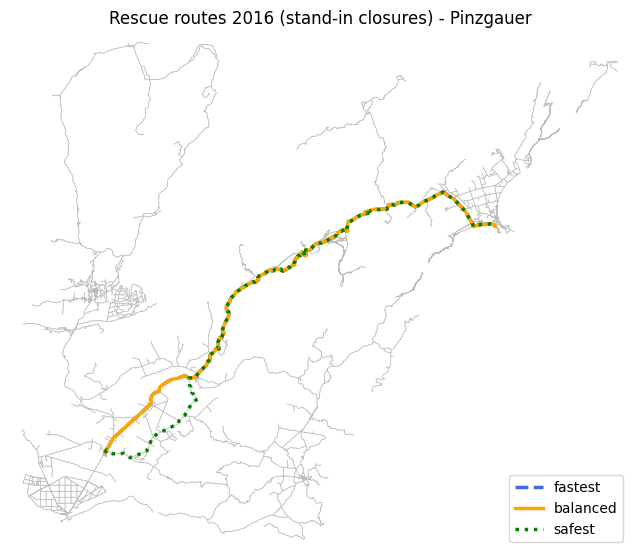

=== rescue_route: MHOV (Rheinmetall MAN HX60), 3 blockages | layers: offline cache (RM5), rivers (RM7), road cells passable (linking fixes)
Terrain 800x800 cells @ 20 m loaded offline from terrain_1660460_5314420_1676460_5330420_20.npz
River layer: 1.1% of cells are mapped water
cut-segment end 2938331135: 8 off-road bypass links
cut-segment end 8247358995: 0 off-road bypass links
cut-segment end 8247359005: 0 off-road bypass links
cut-segment end 8256057275: 23 off-road bypass links
cut-segment end 10934493645: 0 off-road bypass links
cut-segment end 10934493646: 0 off-road bypass links
Terrain 800x800 cells @ 20 m loaded offline from terrain_1635400_5289040_1651400_5305040_20.npz
River layer: 1.2% of cells are mapped water
cut-segment end 267862981: 25 off-road bypass links
cut-segment end 544967705: 1 off-road bypass links
cut-segment end 544967730: 0 off-road bypass links
cut-segment end 544967792: 0 off-road bypass links
cut-segment end 544967844: 0 off-road bypass links
cut-segme

In [56]:
### Risk mitigation 12 - one call that runs everything in the right order: rescue_route()
"""
Running cells out of order can leave old versions of functions in place. rescue_route() takes every input
explicitly and runs the steps in a fixed order on a copy of the road graph:

  1. damaged-road speeds (RM6)       5. blocked probabilities + bridges/weight (RM1, RM4)
  2. slips cut roads, caution ring,  6. confidence-aware cost (RM1)
     off-road bypass (RM10)          7. hazard (RM2, cached per road)
  3. caution ring slows roads (RM10) 8. three routes: fastest / balanced / safest (RM2)
  4. start/goal: off-road access or  9. air comparison (RM11)
     reachable snap (RM9)
Terrain comes through the offline cache and river layer (RM5, RM7) automatically.
The terrain's road cells come from the G_roads you pass in (not the Phase 1 G).
"""
_HAZARD_CACHE = {}


##### Which mitigation wrappers are live - a quick run-order check
def active_layers():
    """Which mitigation wrappers are live - a quick run-order check."""
    return {"offline cache (RM5)": "_rm5_online_terrain" in globals(),
            "rivers (RM7)": "_rm7_terrain_no_rivers" in globals(),
            "road cells passable (linking fixes)": "_build_offroad_graph_base" in globals()}


##### Plan rescue routes: run every risk layer in a fixed order on a copy of the road graph
def rescue_route(G_roads, start_lonlat, goal_lonlat, blockages=(), p_by_edge=None, vehicle="pinzgauer",
                 allow_offroad=True, damage_factor=None, use_hazard=True, window_m=15000):
    """
    Plan rescue routes on a copy of G_roads. Returns dict(graph, routes, start, goal, air_min).
    """
    global load_terrain, VEHICLE
    print(f"=== rescue_route: {VEHICLES[vehicle]['label']}, {len(blockages)} blockages | layers: "
          + ", ".join(k for k, v in active_layers().items() if v))
    _lt_saved, _veh_saved = load_terrain, VEHICLE
    try:
        VEHICLE = vehicle
        load_terrain = lambda cx, cy, half_m=None, res=None: mark_roads(_load_terrain_base(cx, cy, half_m, res), G_roads)
        ##### 1. damaged-road speeds
        Gw = apply_damage_speeds(G_roads, default=damage_factor) if damage_factor else G_roads.copy()
        ##### 2-3. slips: cut roads (+ ring), off-road bypass, slow the ring
        if len(blockages):
            if allow_offroad:
                for b in blockages:                       # one terrain window per slip (slips can be far apart)
                    bb = b.buffer(TERRAIN_RING_M)
                    ends_b = {n for u, v, k, d in Gw.edges(keys=True, data=True)
                              if not d.get("offroad") and edge_geom(Gw, u, v, d).intersects(bb) for n in (u, v)}
                    if not ends_b:
                        continue
                    c = bb.centroid
                    reach = max(math.dist((c.x, c.y), (Gw.nodes[n]["x"], Gw.nodes[n]["y"])) for n in ends_b)
                    block_and_bypass_buffered(Gw, [b], window_m=min(max(WINDOW_M, reach + 1000), window_m))
            else:
                grown = unary_union([b.buffer(TERRAIN_RING_M) for b in blockages])
                Gw.remove_edges_from([(u, v, k) for u, v, k, d in Gw.edges(keys=True, data=True)
                                      if edge_geom(Gw, u, v, d).intersects(grown)])
            slow_near_slips(Gw, list(blockages))
        ##### 4. start and goal
        ends = {}
        for role, ll, nid in (("start", start_lonlat, "rescue_start"), ("end", goal_lonlat, "rescue_goal")):
            n0, d0 = snap(Gw, ll)
            if d0 > SNAP_LIMIT_M and allow_offroad:
                add_offroad_point(Gw, ll, nid, role); ends[role] = nid
            else:
                ends[role] = n0
                if d0 > SNAP_WARN_M:
                    print(f"{role}: WARNING snapped {d0:.0f} m to the nearest road")
        s, g = ends["start"], ends["end"]
        ##### 5-6. probabilities, bridges, weight limits, expected cost
        set_block_probabilities(Gw, p_by_edge=p_by_edge, slips=list(blockages))
        nb, nc = apply_bridge_rules(Gw, vehicle)
        apply_risk_cost(Gw)
        if not nx.has_path(Gw, s, g):
            try:
                g, dg2, note = snap_reachable(Gw, goal_lonlat, s, role="end")
                print(f"goal re-snapped: {note}")
            except nx.NetworkXNoPath:
                g = None
        ##### 7. hazard (cached per road segment)
        if use_hazard:
            key = id(G_roads)
            if key not in _HAZARD_CACHE:
                Gh = G_roads.copy(); compute_hazard(Gh)
                _HAZARD_CACHE[key] = {(u, v, k): d["hazard"] for u, v, k, d in Gh.edges(keys=True, data=True)}
            hz = _HAZARD_CACHE[key]
            for u, v, k, d in Gw.edges(keys=True, data=True):
                d["hazard"] = hz.get((u, v, k), 0.0) if not d.get("offroad") else 0.0
        ##### 8-9. routes and air comparison
        xy = lambda n: (Gw.nodes[n]["x"], Gw.nodes[n]["y"])
        if g is None:
            routes, fast_min = {"fastest": None, "balanced": None, "safest": None}, None
            print("No ground route.")
        else:
            routes = three_routes(Gw, s, g)
            fast_min = (route_cost_breakdown(Gw, routes["fastest"], "w_fastest")[0] / 60) if routes["fastest"] else None
        gx = xy(g) if g is not None else Transformer.from_crs("EPSG:4326", CRS_NZTM, always_xy=True).transform(*goal_lonlat)
        print(f"{nb} bridge segments flagged, {nc} closed by weight. Air: " + ground_vs_air(fast_min, xy(s), gx))
        return {"graph": Gw, "routes": routes, "start": s, "goal": g, "air_min": air_option(xy(s), gx)}
    finally:
        load_terrain, VEHICLE = _lt_saved, _veh_saved


##### Map of the three routes (blue dashed = fastest, orange = balanced, green = safest)
def plot_routes(res, title, out_png):
    """Map of the three routes (blue dashed = fastest, orange = balanced, green = safest)."""
    Gw = res["graph"]
    fig, ax = ox.plot_graph(Gw.subgraph([n for n, d in Gw.nodes(data=True) if not d.get("offroad_point")]),
                            node_size=0, edge_color="#bbbbbb", edge_linewidth=0.4, show=False, close=False, bgcolor="white")
    for name, col, ls in (("fastest", "royalblue", "--"), ("balanced", "orange", "-"), ("safest", "green", ":")):
        r = res["routes"].get(name)
        if not r:
            continue
        xs, ys = [], []
        for a, b in zip(r[:-1], r[1:]):
            d = min(Gw[a][b].values(), key=lambda e: e.get(f"w_{name}", math.inf))
            gx_, gy_ = edge_geom(Gw, a, b, d).xy; xs += list(gx_); ys += list(gy_)
        ax.plot(xs, ys, color=col, lw=2.5, ls=ls, label=name, zorder=3)
    ax.legend(loc="lower right"); ax.set_title(title)
    fig.savefig(out_png, dpi=150, bbox_inches="tight"); plt.show()


##### The 2016 hard case (needs test 3 above): SH1 slips + Inland Road closure, calibrated road speeds
if "G_inc" in globals() and "closure_C" in globals():
    print("Run-order check:", active_layers())
    for veh in ("pinzgauer", "mhov"):
        res_12 = rescue_route(G_inc, inc_pts["start"][:2], inc_pts["goal"][:2],
                              blockages=INC_BLOCKAGES + [closure_C], vehicle=veh, damage_factor=CONVOY_CALIBRATION)
        if veh == "pinzgauer" and res_12["routes"]["fastest"]:
            plot_routes(res_12, "Rescue routes 2016 (stand-in closures) - Pinzgauer", "rescue_routes_pinzgauer.png")


In [57]:
### Apply the NO-GO mask
##### Risk mitigation 13 - every terrain window honours every slip
"""
Found in the workflow-slide check: only the window that block_and_bypass() loads for a slip had that slip
made NO-GO. Two gaps:
  1. Windows loaded for an off-road start or goal (add_offroad_point) had no slip mask at all.
  2. In rescue_route() each slip gets its own window, which masked that slip only, not a neighbouring one.
Road cells come from the uncut road graph (mark_roads), so in both cases an off-road link could run along a
cut road straight through a slip.
Fix: while rescue_route() runs, every terrain window it loads has every slip (grown by TERRAIN_RING_M) set
to NO-GO (no elevation). Cells without elevation lose both graded moves and road-to-road moves.
Not covered: the optional walking leg is a straight line and can still cross a slip.
"""
from rasterio.features import geometry_mask

NO_GO_ZONES = []          # NZTM polygons; set by rescue_route() below for the length of a call, empty otherwise


### Changed for Risk mitigation 13 from _load_terrain_base (slip mask only inside block_and_bypass) to one that
### also masks every polygon in NO_GO_ZONES, to allow for start/goal windows and windows that overlap other slips.
if "_rm13_terrain_unmasked" not in globals():
    _rm13_terrain_unmasked = _load_terrain_base       # the cached + rivers loader (Risk mitigations 5 and 7)

##### Terrain window as before, with every cell inside NO_GO_ZONES set to no elevation (NO-GO)
def _load_terrain_base(cx, cy, half_m=None, res=None):
    """Terrain window as before, with every cell inside NO_GO_ZONES set to no elevation (NO-GO)."""
    t = _rm13_terrain_unmasked(cx, cy, half_m, res)
    if NO_GO_ZONES:
        inside = ~geometry_mask(NO_GO_ZONES, out_shape=t["shape"], transform=t["transform"])
        if inside.any():
            t = dict(t); t["dem"] = t["dem"].copy(); t["dem"][inside] = np.nan
            print(f"NO-GO mask: {inside.mean():.1%} of this window is inside a slip zone")
    return t


### Changed for Risk mitigation 13 from rescue_route (Risk mitigation 12, no window-wide slip mask) to a wrapper
### that fills NO_GO_ZONES from its blockages during the call, to allow for every terrain window honouring every slip.
if "_rm13_rescue_route_unmasked" not in globals():
    _rm13_rescue_route_unmasked = rescue_route

##### Rescue_route() from Risk mitigation 12, with every slip NO-GO in every terrain window
def rescue_route(G_roads, start_lonlat, goal_lonlat, blockages=(), *args, **kwargs):
    """rescue_route() from Risk mitigation 12, with every slip NO-GO in every terrain window."""
    global NO_GO_ZONES
    saved = NO_GO_ZONES
    NO_GO_ZONES = [b.buffer(TERRAIN_RING_M) for b in blockages]
    try:
        return _rm13_rescue_route_unmasked(G_roads, start_lonlat, goal_lonlat, blockages, *args, **kwargs)
    finally:
        NO_GO_ZONES = saved


##### Number of off-road (non-walking) edges in a rescue_route() result whose path crosses a slip
def offroad_through_slips(res, blockages):
    """Number of off-road (non-walking) edges in a rescue_route() result whose path crosses a slip."""
    Gw = res["graph"]
    return sum(1 for u, v, d in Gw.edges(data=True)
               if d.get("offroad") and not d.get("foot") and d.get("geometry") is not None
               and any(d["geometry"].intersects(b) for b in blockages))


##### Self-test: a masked window has no elevation inside the zone, and the cached original is untouched
def _rm13_selftest():
    global NO_GO_ZONES
    saved = NO_GO_ZONES
    try:
        n0 = next(iter(G.nodes)); cx, cy = float(G.nodes[n0]["x"]), float(G.nodes[n0]["y"])   # a Phase 1 road node
        zone = Point(cx, cy).buffer(300)
        NO_GO_ZONES = []
        t0 = _load_terrain_base(cx, cy, 2000, 20)
        NO_GO_ZONES = [zone]
        t1 = _load_terrain_base(cx, cy, 2000, 20)
        c = xy_to_cell(t1, cx, cy)
        r, k = divmod(c, t1["shape"][1])
        assert np.isnan(t1["dem"][r, k]), "centre of the zone should be NO-GO"
        assert np.isfinite(t0["dem"]).sum() > np.isfinite(t1["dem"]).sum(), "mask should remove cells"
        corner = t1["dem"][0, 0]
        assert np.isfinite(corner) or np.isnan(t0["dem"][0, 0]), "cells outside the zone should be unchanged"
        print("RM13 self-test passed: cells inside the slip zone are NO-GO, the rest are unchanged")
    finally:
        NO_GO_ZONES = saved

_rm13_selftest()

##### The 2016 hard case again (needs test 3 above): no off-road link may cross a slip
if "G_inc" in globals() and "closure_C" in globals():
    slips_2016 = INC_BLOCKAGES + [closure_C]
    res_13 = rescue_route(G_inc, inc_pts["start"][:2], inc_pts["goal"][:2], blockages=slips_2016,
                          vehicle="pinzgauer", damage_factor=CONVOY_CALIBRATION)
    n_cross = offroad_through_slips(res_13, slips_2016)
    print(f"Off-road links crossing a slip with the NO-GO mask: {n_cross} (should be 0)")


DEM sources: Kaikoura 2016-17 lidar 52%, national 1 m 23%, national 8 m 0%, none 26%
Terrain 200x200 cells @ 20 m | lidar coverage 74% | land cover coverage 100%
River layer: none loaded (ResponseStatusCodeError)
River layer: 0.0% of cells are mapped water
Terrain 200x200 cells @ 20 m loaded offline from terrain_1639400_5291140_1643400_5295140_20.npz
River layer: 0.0% of cells are mapped water
NO-GO mask: 1.7% of this window is inside a slip zone
RM13 self-test passed: cells inside the slip zone are NO-GO, the rest are unchanged
=== rescue_route: Pinzgauer (NZLOV), 3 blockages | layers: offline cache (RM5), rivers (RM7), road cells passable (linking fixes)
Terrain 800x800 cells @ 20 m loaded offline from terrain_1660460_5314420_1676460_5330420_20.npz
River layer: 1.1% of cells are mapped water
NO-GO mask: 0.4% of this window is inside a slip zone
cut-segment end 2938331135: 8 off-road bypass links
cut-segment end 8247358995: 0 off-road bypass links
cut-segment end 8247359005: 0 off-roa

In [61]:
### Risk mitigation 13b - no free off-road link inside a NO-GO cell
"""
Found on the 19 Oct 2026 run: the 2016 hard case above still had 2 off-road edges crossing a slip (should be 0).
Both were one 18 m link (one edge each way) between two cut-segment ends that sit in the same 20 m cell inside
the Goose Bay slip. add_offroad_links() runs Dijkstra from the source cell, and the source cell always has
distance 0 even when it is NO-GO, so any road node in that same cell got a link. The two nodes had no other
roads (every edge touching a slip is cut), so no route changed - but it broke the NO-GO rule.
Fix: a vehicle cannot start, end or wait in a cell with no elevation (NO-GO), so add_offroad_links() now
skips a source or a target in such a cell.
"""

### Changed for Risk mitigation 13b from add_offroad_links (links to any road node in the source cell, even a
### NO-GO cell) to one that skips NO-GO source and target cells, to allow for slips that cover whole cells.
if "_rm13b_links_unchecked" not in globals():
    _rm13b_links_unchecked = add_offroad_links      # the Phase 2 linking version

##### True if grid cell c has no elevation (NO-GO: slip, river mask or no data)
def _nogo_cell(t, c):
    """True if grid cell c has no elevation (NO-GO: slip, river mask or no data)."""
    return not np.isfinite(t["dem"].ravel()[c])

##### Add_offroad_links() as before, but never from or to a NO-GO (no elevation) cell
def add_offroad_links(G, node, t, M, direction="out", exclude=()):
    """add_offroad_links() as before, but never from or to a NO-GO (no elevation) cell."""
    c0 = xy_to_cell(t, G.nodes[node]["x"], G.nodes[node]["y"])
    if c0 is not None and _nogo_cell(t, c0):
        return 0                                     # the vehicle cannot leave a NO-GO cell
    blocked = tuple(n for n, c in _road_nodes_in(G, t) if _nogo_cell(t, c))
    return _rm13b_links_unchecked(G, node, t, M, direction, tuple(exclude) + blocked)


##### The 2016 hard case again (needs test 3 and Risk mitigation 13 above): no off-road link may cross a slip
if "G_inc" in globals() and "closure_C" in globals():
    slips_2016 = INC_BLOCKAGES + [closure_C]
    res_13b = rescue_route(G_inc, inc_pts["start"][:2], inc_pts["goal"][:2], blockages=slips_2016,
                           vehicle="pinzgauer", damage_factor=CONVOY_CALIBRATION)
    n_cross = offroad_through_slips(res_13b, slips_2016)
    print(f"Off-road links crossing a slip with Risk mitigation 13b: {n_cross} (should be 0)")
    assert n_cross == 0, "an off-road link still crosses a slip"


=== rescue_route: Pinzgauer (NZLOV), 3 blockages | layers: offline cache (RM5), rivers (RM7), road cells passable (linking fixes)
Terrain 800x800 cells @ 20 m loaded offline from terrain_1660460_5314420_1676460_5330420_20.npz
River layer: 1.1% of cells are mapped water
NO-GO mask: 0.4% of this window is inside a slip zone
cut-segment end 2938331135: 8 off-road bypass links
cut-segment end 8247358995: 0 off-road bypass links
cut-segment end 8247359005: 0 off-road bypass links
cut-segment end 8256057275: 23 off-road bypass links
cut-segment end 10934493645: 0 off-road bypass links
cut-segment end 10934493646: 0 off-road bypass links
Terrain 800x800 cells @ 20 m loaded offline from terrain_1635400_5289040_1651400_5305040_20.npz
River layer: 1.2% of cells are mapped water
NO-GO mask: 0.4% of this window is inside a slip zone
cut-segment end 267862981: 25 off-road bypass links
cut-segment end 544967705: 0 off-road bypass links
cut-segment end 544967730: 0 off-road bypass links
cut-segment e

In [58]:
##### TEMP setup (will be removed): restore the AOI files after a runtime reset
!test -f kaikoura_aoi.shp || (git clone -q https://github.com/Loading-my-brain/x-band.git /tmp/xb && cp /tmp/xb/kaikoura_road_route/* . && for e in shp shx dbf prj cpg qmd; do cp Kaikoura.$e kaikoura_aoi.$e; done)
!ls kaikoura_aoi.*

kaikoura_aoi.cpg  kaikoura_aoi.prj  kaikoura_aoi.shp
kaikoura_aoi.dbf  kaikoura_aoi.qmd  kaikoura_aoi.shx
